# Modelo final

**Objetivo.** Entrenar, justificar y evaluar el **modelo final** del proyecto incorporando lo que aprendimos en los cuadernos `03_preprocesamiento`, `05_hiperparametros` y `07_evaluacion`:

- quitar `MKT_margin` (variable que cambia con el año, PSI 0.6–1.5);
- probar **Pinnacle** (la casa de menor margen) como precio de referencia, con el consenso de las demás casas como respaldo cuando Pinnacle no publica;
- elegir el hiperparámetro de regularización con **validación temporal anidada**;
- evaluar con **todas** las métricas: log loss, RPS, Brier, AUC, ECE, pendiente de calibración, por temporada y por liga, con intervalos por bloques y corrección de Benjamini–Hochberg;
- entrenar **solo con train/val** (2014/15–2023/24), **guardar** el modelo y mostrar cómo usarlo con cuotas nuevas;
- **evaluar una única vez en el test holdout** (2024/25 y 2025/26), que nunca participó en ninguna decisión.

**Cómo leer este cuaderno.** Cada celda de código va precedida por una celda de texto (qué vamos a hacer y por qué) y seguida por otra (qué encontramos y qué puede significar para nuestro caso).

| Paso | Qué hace |
|---|---|
| 0 | Carga y utilidades |
| 1 | Construcción del precio de referencia (Pinnacle con respaldo de consenso) |
| 2 | Candidatos y regla de elección del modelo final |
| 3 | Elección de la regularización con validación anidada |
| 4 | Evaluación completa fuera de muestra (6 temporadas de validación) |
| 5 | Diagnóstico: curvas ROC, calibración, estabilidad y desempeño por liga |
| 6 | Backtest de apuestas |
| 7 | Entrenamiento final (solo train/val), guardado y uso con cuotas nuevas |
| 8 | **Evaluación en el test holdout** (2024/25–2025/26): métricas, por temporada, por liga, calibración, backtest |

**Entrada.** `dataset_final.csv` (dividido en `split/train_val.csv` y `split/test.csv` por `scripts/split_holdout.py`), `matches_sq.csv`, `backtest_odds.csv`, `feature_sets.json`, `modelos_oof.csv`. **Salida.** `modelo_final.json` (coeficientes y escalado), `modelo_final.joblib`, `modelo_final_oof.csv` (predicciones fuera de muestra en validación), `modelo_final_test.csv` (predicciones en el test holdout).

> **Terminología (igual en todo el proyecto).** *Referencias sin aprendizaje*: el **prior** (frecuencias de H/D/A del entrenamiento) y el **mercado crudo** (probabilidades implícitas de las cuotas). ***Baseline***: la **regresión logística sobre las tres variables de mercado** (`MKT_logit`, `MKT_pD`, `MKT_margin`; "LR (cuotas)"), el modelo más simple con aprendizaje, contra el que se comparan HGB, XGBoost, SVM, MLP y el ensemble. **Modelo final**: regresión logística de dos variables (`REF_logit`, `REF_pD`) sobre la apertura de Pinnacle.

> **Esquema train/val/test (test holdout).** Las dos últimas temporadas, **2024/25 y 2025/26** (5,999 partidos, 16.6 % de los 36,119), se reservan como **test final**: no se usan para entrenar, validar, elegir hiperparámetros, variables ni umbrales, y solo se evalúan **una vez** en `08_modelo_final.ipynb` (Paso 8). Todo lo demás —**30,120 partidos, 2014/15–2023/24**— es *train/val*: los folds de validación son las seis temporadas **2018/19–2023/24** (cada una se valida con todo lo anterior). Los cuadernos 04–08 definen `TEST_SEASONS = [2425, 2526]` y `TEST_MASK`; ningún ajuste (`fit`) puede ver una fila de test porque los folds terminan en 2023/24.

## Paso 0 — Carga y utilidades

**Qué vamos a hacer.** Cargar los datos y definir las utilidades que se reutilizan: validación temporal expansiva (6 folds, 2018/19–2023/24; las temporadas 2024/25 y 2025/26 quedan fuera como **test holdout**), métricas (log loss, RPS, Brier, AUC, ECE) y comparación pareada con intervalo por **bootstrap de bloques** (temporada–semana) con corrección de Benjamini–Hochberg.

**Por qué.** Para que el modelo final se mida con exactamente la misma vara que todo lo anterior y los números sean comparables con `04_modelo` y `07_evaluacion`.

In [1]:
import json, warnings, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import log_loss, roc_auc_score, roc_curve, accuracy_score, balanced_accuracy_score

warnings.filterwarnings('ignore')
DATA = '../data/'
df = pd.read_csv(DATA + 'dataset_final.csv'); odds = pd.read_csv(DATA + 'backtest_odds.csv')
fs = json.load(open(DATA + 'feature_sets.json')); HP = json.load(open(DATA + 'hiperparametros.json'))
y = df['FTR'].map({'H': 0, 'D': 1, 'A': 2}).to_numpy(); seas = df['Season'].to_numpy(); liga = df['Div'].to_numpy()
TEST_SEASONS = [2425, 2526]; TEST_MASK = np.isin(seas, TEST_SEASONS); TV = ~TEST_MASK   # test holdout: se usa SOLO en el Paso 8
TEMP = sorted(np.unique(seas)); TEMP_TV = [s for s in TEMP if s not in TEST_SEASONS]
FOLDS = [s for s in TEMP if s >= 1819 and s not in TEST_SEASONS]; EV = (seas >= 1819) & TV
assert max(FOLDS) < min(TEST_SEASONS)
# la division en archivos (scripts/split_holdout.py) coincide con las mascaras de este cuaderno
_tv, _te = pd.read_csv(DATA + 'split/train_val.csv'), pd.read_csv(DATA + 'split/test.csv')
assert len(_tv) == int(TV.sum()) and len(_te) == int(TEST_MASK.sum()) and set(_te['Season']) == set(TEST_SEASONS) and not set(_tv['Season']) & set(TEST_SEASONS)
assert (_tv[['Date', 'HomeTeam', 'AwayTeam']].values == df.loc[TV, ['Date', 'HomeTeam', 'AwayTeam']].values).all() and (_te[['Date', 'HomeTeam', 'AwayTeam']].values == df.loc[TEST_MASK, ['Date', 'HomeTeam', 'AwayTeam']].values).all()
fechas = pd.to_datetime(df['Date'], dayfirst=True, format='mixed')
bloque = pd.factorize(df['Season'].astype(str) + '-' + fechas.dt.isocalendar().week.astype(str).to_numpy())[0]
rng = np.random.default_rng(88)

def cv_proba(fab, X, folds=FOLDS):
    Pm = np.full((len(y), 3), np.nan)
    for s in folds:
        tr, va = seas < s, seas == s
        Pm[va] = fab().fit(X[tr], y[tr]).predict_proba(X[va])
    return Pm
def loss_vec(Pm):
    o = np.full(len(y), np.nan); ok = ~np.isnan(Pm[:, 0]); o[ok] = -np.log(np.clip(Pm[ok, y[ok]], 1e-9, 1)); return o
def rps(Pm, yv):
    O = np.eye(3)[yv]; return float(np.mean(0.5 * (((np.cumsum(Pm, 1) - np.cumsum(O, 1))[:, :2]) ** 2).sum(1)))
def brier(Pm, yv): return float(np.mean(np.sum((Pm - np.eye(3)[yv]) ** 2, axis=1)))
def aucs(Pm, yv): return [roc_auc_score(yv == j, Pm[:, j]) for j in range(3)]
def ece_w(p, o, nb=10):
    b = np.minimum((p * nb).astype(int), nb - 1); return float(sum((b == k).mean() * abs(o[b == k].mean() - p[b == k].mean()) for k in np.unique(b)))
def ece_q(p, o, nb=10):
    b = pd.qcut(p, nb, labels=False, duplicates='drop'); return float(sum((b == k).mean() * abs(o[b == k].mean() - p[b == k].mean()) for k in np.unique(b)))
def pend(p, o):
    pc = np.clip(p, 1e-6, 1 - 1e-6); m = LogisticRegression(C=1e6, max_iter=1000).fit(np.log(pc / (1 - pc)).reshape(-1, 1), o); return float(m.coef_[0, 0])
def comparar(la, lb, B=2000, mask=None):
    ok = ~np.isnan(la) & ~np.isnan(lb)
    if mask is not None: ok &= mask
    d = (la - lb)[ok]; b = bloque[ok]; cod, K = pd.factorize(b)[0], len(np.unique(b))
    sm = np.bincount(cod, weights=d, minlength=K); cn = np.bincount(cod, minlength=K).astype(float)
    ix = rng.integers(0, K, (B, K)); bs = sm[ix].sum(1) / cn[ix].sum(1); fo = pd.Series(d).groupby(seas[ok]).mean()
    p = float(max(2 * min((bs <= 0).mean(), (bs >= 0).mean()), 1 / B))
    return dict(delta=float(d.mean()), lo=float(np.percentile(bs, 2.5)), hi=float(np.percentile(bs, 97.5)), folds=f'{int((fo < 0).sum())}/{len(fo)}', p=p)
def bh(p):
    p = np.asarray(p); o = np.argsort(p); m = len(p); adj = np.empty(m); adj[o] = np.minimum.accumulate((p[o] * m / (np.arange(m) + 1))[::-1])[::-1]; return np.minimum(adj, 1)
lr = lambda C: (lambda: make_pipeline(StandardScaler(), LogisticRegression(C=C, max_iter=5000)))
print('filas:', len(df), '| folds:', [int(s) for s in FOLDS], '| partidos de evaluacion (validacion):', int(EV.sum()))
print('train/val:', int(TV.sum()), '| test holdout (no se toca hasta el Paso 8):', int(TEST_MASK.sum()), TEST_SEASONS)

def forest(ax, nombres, delta, lo, hi, titulo, xlabel='Δ log loss (negativo = mejor que la referencia)', fmt='{:+.4f}', positivo_bueno=False):
    """Delta con IC (95%): verde = mejora distinguible del ruido, rojo = empeora, gris = indistinguible (con positivo_bueno=True se invierte el sentido); la referencia (sin IC) va en negro."""
    ypos = np.arange(len(nombres))[::-1]
    for yi, d, l, h in zip(ypos, delta, lo, hi):
        ref = (l == h == 0) or np.isnan(l)
        bueno_, malo_ = (l > 0, h < 0) if positivo_bueno else (h < 0, l > 0)
        c = 'black' if ref else ('tab:green' if bueno_ else 'tab:red' if malo_ else 'gray')
        if not ref: ax.plot([l, h], [yi, yi], color=c, lw=2.2)
        ax.plot(d, yi, 'o' if not ref else 's', color=c, ms=5)
        ax.annotate(fmt.format(d), (d if ref else max(d, h), yi), xytext=(4, 0), textcoords='offset points', va='center', fontsize=7, color=c)
    ax.axvline(0, color='k', lw=0.8); ax.set_yticks(ypos); ax.set_yticklabels(nombres, fontsize=8); ax.set_title(titulo, fontsize=10); ax.set_xlabel(xlabel, fontsize=8)
    ax.margins(x=0.18)

filas: 36119 | folds: [1819, 1920, 2021, 2122, 2223, 2324] | partidos de evaluacion (validacion): 18184
train/val: 30120 | test holdout (no se toca hasta el Paso 8): 5999 [2425, 2526]


**Qué encontramos.** 36,119 partidos: **30,120 de train/val** (2014/15–2023/24) y **5,999 de test holdout** (2024/25–2025/26, que no se toca hasta el Paso 8). La validación son **6 temporadas** (2018/19–2023/24) con 18,184 partidos, con el mismo esquema que en `04_modelo` y `07_evaluacion`.

**Qué significa para nuestro caso.** Los números de este cuaderno (Pasos 2 a 7) se pueden comparar directamente con los anteriores (mismos partidos, mismos folds); cualquier diferencia viene del modelo, no del esquema de evaluación. El Paso 8 es la única evaluación sobre datos que nunca participaron en una decisión.

## Paso 1 — Precio de referencia: Pinnacle con respaldo del consenso

**Qué vamos a hacer.** Cargar las dos variables de mercado que se construyeron en `02_feature.ipynb` (Paso 11) a partir de las cuotas de **apertura**:

- `REF_logit = ln(pH/pA)` y `REF_pD`, calculadas con las probabilidades normalizadas de **Pinnacle** cuando esa casa publicó las tres cuotas, y con el **consenso de las otras casas** (`MKT_logit`, `MKT_pD`) cuando no.

Se excluye el margen (`MKT_margin`), y se **verifica** que lo cargado coincide con un recálculo independiente hecho aquí.

**Por qué.** En `03_preprocesamiento` Pinnacle sola fue algo mejor que el consenso (−0.0005) pero falta en ~5% de los partidos; el respaldo con el consenso cubre el 100% sin perder esa ventaja. Y el margen cambia con los años (PSI 0.6–1.5): un modelo que lo use aprende "qué año es", no nada sobre el partido.

In [2]:
keycols = ['Season', 'Date', 'HomeTeam', 'AwayTeam']
ms = pd.read_csv(DATA + 'matches_clean.csv', usecols=keycols + ['PSH', 'PSD', 'PSA'])
o2 = df[keycols].merge(ms, on=keycols, how='left', validate='one_to_one')
PS = o2[['PSH', 'PSD', 'PSA']].to_numpy(float); psok = ~np.isnan(PS).any(1)
with np.errstate(all='ignore'):
    inv = 1 / PS; pp = inv / inv.sum(1, keepdims=True)
    ps_logit, ps_pD = np.log(pp[:, 0] / pp[:, 2]), pp[:, 1]
# las variables REF se construyeron en 02_feature (Paso 11): se cargan y se verifican contra un recalculo independiente
EXTRA = pd.read_csv(DATA + 'dataset_extra.csv')
assert (EXTRA[['Date', 'HomeTeam', 'AwayTeam']].values == df[['Date', 'HomeTeam', 'AwayTeam']].values).all()
assert np.allclose(np.where(psok, ps_logit, df['MKT_logit']), EXTRA['REF_logit']) and np.allclose(np.where(psok, ps_pD, df['MKT_pD']), EXTRA['REF_pD'])
df['REF_logit'] = EXTRA['REF_logit'].to_numpy(); df['REF_pD'] = EXTRA['REF_pD'].to_numpy(); df['XIz_DIF'] = EXTRA['XIz_DIF'].to_numpy()
print('partidos con Pinnacle observada:', int(psok.sum()), f'({psok.mean():.1%}) | con respaldo de consenso:', int((~psok).sum()))
print('cobertura de Pinnacle por temporada:', {int(s): round(float(psok[seas == s].mean()), 3) for s in TEMP})
print('correlacion REF_logit vs MKT_logit:', round(float(np.corrcoef(df.REF_logit, df.MKT_logit)[0, 1]), 4), '| REF_pD vs MKT_pD:', round(float(np.corrcoef(df.REF_pD, df.MKT_pD)[0, 1]), 4))
print('NaN en REF:', int(df[['REF_logit', 'REF_pD']].isna().sum().sum()))

partidos con Pinnacle observada: 34447 (95.4%) | con respaldo de consenso: 1672
cobertura de Pinnacle por temporada: {1415: 0.995, 1516: 0.999, 1617: 0.992, 1718: 0.987, 1819: 0.995, 1920: 0.998, 2021: 0.998, 2122: 0.999, 2223: 0.999, 2324: 0.999, 2425: 0.999, 2526: 0.478}
correlacion REF_logit vs MKT_logit: 0.9991 | REF_pD vs MKT_pD: 0.9946
NaN en REF: 0


**Qué encontramos.**

- Pinnacle publicó las tres cuotas de apertura en **95.4%** de los partidos (34,447); en los otros 1,672 se usa el consenso de las demás casas.
- La cobertura es de 99–100% en todas las temporadas salvo **2025/26, donde cae a 47.8%** (Pinnacle dejó de publicar parte de la temporada). En ese caso la mitad de los partidos usa el respaldo.
- Las nuevas variables son casi idénticas a las del consenso (correlación 0.999 en el logit y 0.995 en la probabilidad de empate): no hay un salto de escala entre los dos orígenes, así que mezclar Pinnacle con el respaldo es seguro. No hay NaN.

**Qué significa para nuestro caso.** Podemos usar el precio de la casa más precisa sin perder partidos. Pero hay que recordar que en 2025/26 el modelo final se parece más al consenso que a Pinnacle: la mejora esperada de Pinnacle será menor allí. Si Pinnacle sigue sin publicar en temporadas futuras, el modelo seguirá funcionando igual (con el respaldo).

## Paso 2 — Candidatos y regla de elección

**Qué vamos a hacer.** Comparar cuatro candidatos de regresión logística estandarizada (`C = 0.05`) con la validación temporal:

| Candidato | Variables |
|---|---|
| **A. Baseline** | `MKT_logit`, `MKT_pD`, `MKT_margin` (el de `04_modelo`) |
| **B. Consenso sin margen** | `MKT_logit`, `MKT_pD` |
| **C. Pinnacle con respaldo** | `REF_logit`, `REF_pD` |
| **D. C + plantilla** | C y `DIF_sq_top11` (¿aporta algo sobre el precio?) |

**Regla de elección (definida antes de ver los resultados).** Se toma el candidato de menor log loss; se acepta **solo si** supera al baseline (A) con un IC por bloques que excluye 0 y mejora en al menos 5 de 6 temporadas (el 75 % de los folds, como el 6/8 original). En caso contrario se conserva el más simple sin margen (B).

**Por qué.** Evita elegir por una diferencia de 0.0001 que podría ser ruido, y deja explícito el criterio para el informe.

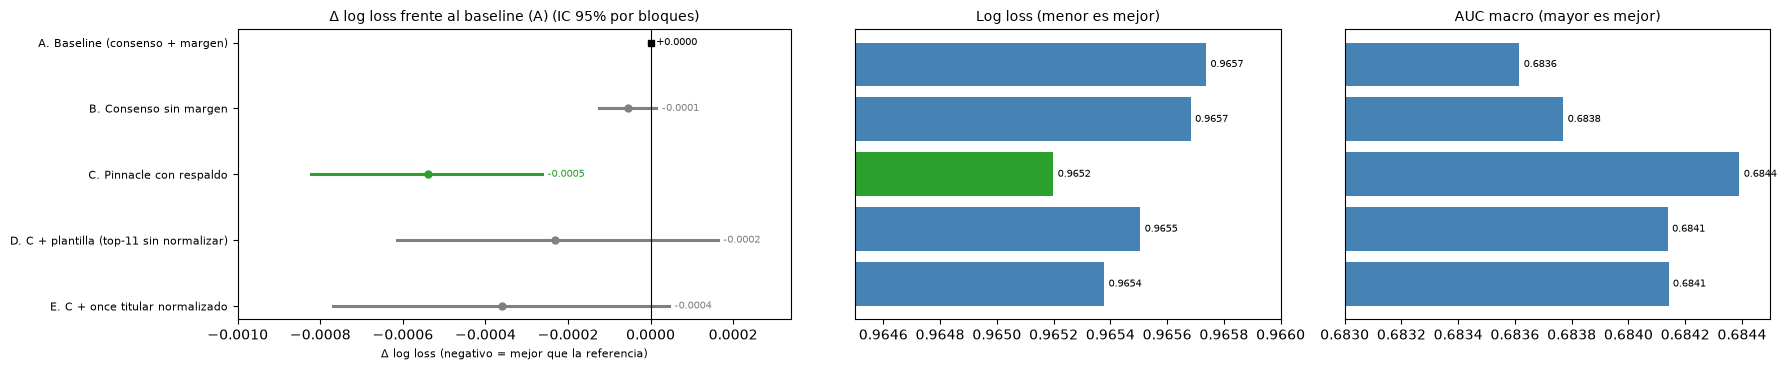


Mejor por log loss: C. Pinnacle con respaldo | cumple la regla (IC excluye 0 y >= 5/6 folds): True
MODELO FINAL -> C. Pinnacle con respaldo ['REF_logit', 'REF_pD']


In [3]:
CAND = {'A. Baseline (consenso + margen)': ['MKT_logit', 'MKT_pD', 'MKT_margin'],
        'B. Consenso sin margen': ['MKT_logit', 'MKT_pD'],
        'C. Pinnacle con respaldo': ['REF_logit', 'REF_pD'],
        'D. C + plantilla (top-11 sin normalizar)': ['REF_logit', 'REF_pD', 'DIF_sq_top11'],
        'E. C + once titular normalizado': ['REF_logit', 'REF_pD', 'XIz_DIF']}
PC = {k: cv_proba(lr(0.05), df[v].to_numpy(float)) for k, v in CAND.items()}
LC = {k: loss_vec(p) for k, p in PC.items()}
A_ = 'A. Baseline (consenso + margen)'
filas = []
for k in CAND:
    c = comparar(LC[k], LC[A_]) if k != A_ else dict(delta=0.0, lo=np.nan, hi=np.nan, folds='-', p=np.nan)
    filas.append(dict(candidato=k, log_loss=np.nanmean(LC[k][EV]), rps=rps(PC[k][EV], y[EV]), AUC_macro=np.mean(aucs(PC[k][EV], y[EV])), delta_vs_A=c['delta'],
                      IC=f"[{c['lo']:+.4f}, {c['hi']:+.4f}]" if k != A_ else '-', folds_mejora=c['folds']))
tc = pd.DataFrame(filas).set_index('candidato')
cA = {k: (comparar(LC[k], LC[A_]) if k != A_ else dict(delta=0.0, lo=0.0, hi=0.0)) for k in CAND}
fig, axs = plt.subplots(1, 3, figsize=(18, 3.8), gridspec_kw={'width_ratios': [1.3, 1, 1]})
forest(axs[0], list(CAND), [cA[k]['delta'] for k in CAND], [cA[k]['lo'] for k in CAND], [cA[k]['hi'] for k in CAND], 'Δ log loss frente al baseline (A) (IC 95% por bloques)')
for ax, col, tit, lim in ((axs[1], 'log_loss', 'Log loss (menor es mejor)', (0.9645, 0.9660)), (axs[2], 'AUC_macro', 'AUC macro (mayor es mejor)', (0.6830, 0.6845))):
    ax.barh(range(len(tc))[::-1], tc[col], color=['tab:green' if k == tc[col].idxmin() and col == 'log_loss' else 'steelblue' for k in tc.index]); ax.set_xlim(*lim); ax.set_yticks([])
    for yi, v in zip(range(len(tc))[::-1], tc[col]): ax.text(v + (lim[1] - lim[0]) * 0.01, yi, f'{v:.4f}', va='center', fontsize=7)
    ax.set_title(tit, fontsize=10)
plt.tight_layout(); plt.show()
mejor = tc.log_loss.idxmin()
c = comparar(LC[mejor], LC[A_]); acepta = (mejor != A_) and (c['hi'] < 0) and (int(c['folds'].split('/')[0]) >= int(np.ceil(0.75 * len(FOLDS))))
FINAL = mejor if acepta else 'B. Consenso sin margen'
FINAL_COLS = CAND[FINAL]
print(f"\nMejor por log loss: {mejor} | cumple la regla (IC excluye 0 y >= 5/6 folds): {acepta}")
print('MODELO FINAL ->', FINAL, FINAL_COLS)

**Qué encontramos.**

| Candidato | Log loss | AUC macro | Δ vs. A | IC 95% (bloques) | Folds |
|---|---|---|---|---|---|
| A. Baseline (consenso + margen) | 0.9657 | 0.6836 | — | — | — |
| B. Consenso sin margen | 0.9657 | 0.6838 | −0.0001 | [−0.0001, +0.0000] | 4/6 |
| **C. Pinnacle con respaldo** | **0.9652** | **0.6844** | **−0.0005** | [−0.0008, −0.0003] | 6/6 |
| D. C + plantilla (top-11 sin normalizar) | 0.9655 | 0.6841 | −0.0002 | [−0.0006, +0.0001] | 5/6 |
| E. C + once titular normalizado | 0.9654 | 0.6841 | −0.0004 | [−0.0007, +0.0000] | 5/6 |

El mejor es C y **cumple la regla** definida de antemano (IC que excluye 0 y mejora en 6 de 6 temporadas). Añadir la plantilla, sea el top-11 sin normalizar (D, 0.9655) o el **once titular normalizado** (E, 0.9654), empeora respecto a C (0.9652): una vez más, no aporta nada sobre el precio.

**Qué significa para nuestro caso.** El modelo final queda con **solo dos variables**: `REF_logit` y `REF_pD`. La mejora sobre el baseline (LR de tres variables) es real pero **pequeña** (0.0005 de log loss, un 0.05%): refina el precio, no descubre información nueva. Que la plantilla siga sin aportar confirma, con el mejor precio disponible, el resultado central del proyecto: lo que sabemos del equipo ya está en la cuota.

## Paso 2b — ¿Mejora el modelo con una corrección distinta por liga?

**Qué vamos a hacer.** Hasta ahora el modelo aprende **una sola** transformación del precio para las nueve ligas. Probar dos formas de dejar que cada liga tenga su propio desplazamiento (intercepto), partiendo del candidato C (Pinnacle con respaldo):

| Candidato | Qué es |
|---|---|
| **C** (el actual) | `REF_logit`, `REF_pD` |
| **F. C + liga (indicadoras)** | C más 8 columnas 0/1, una por liga menos la de referencia; el modelo aprende un coeficiente por liga |
| **G. C + liga con encogimiento** | igual que F, pero con las indicadoras escaladas a la mitad de ese tamaño: la regularización las penaliza más y solo se desvía de la corrección común si hay evidencia clara (*shrinkage*) |

**Regla de elección (fijada antes de ver los resultados).** Un candidato con liga reemplaza a C solo si su diferencia de log loss frente a C tiene un IC por bloques que excluye 0 **y** mejora en al menos 5 de 6 temporadas.

**Por qué.** En el Paso 4 se verá que la mejora sobre el mercado viene casi toda de Portugal y Turquía; si esas ligas tienen un sesgo propio y estable, un intercepto por liga lo captura. Todo se estima solo con partidos anteriores a cada temporada.

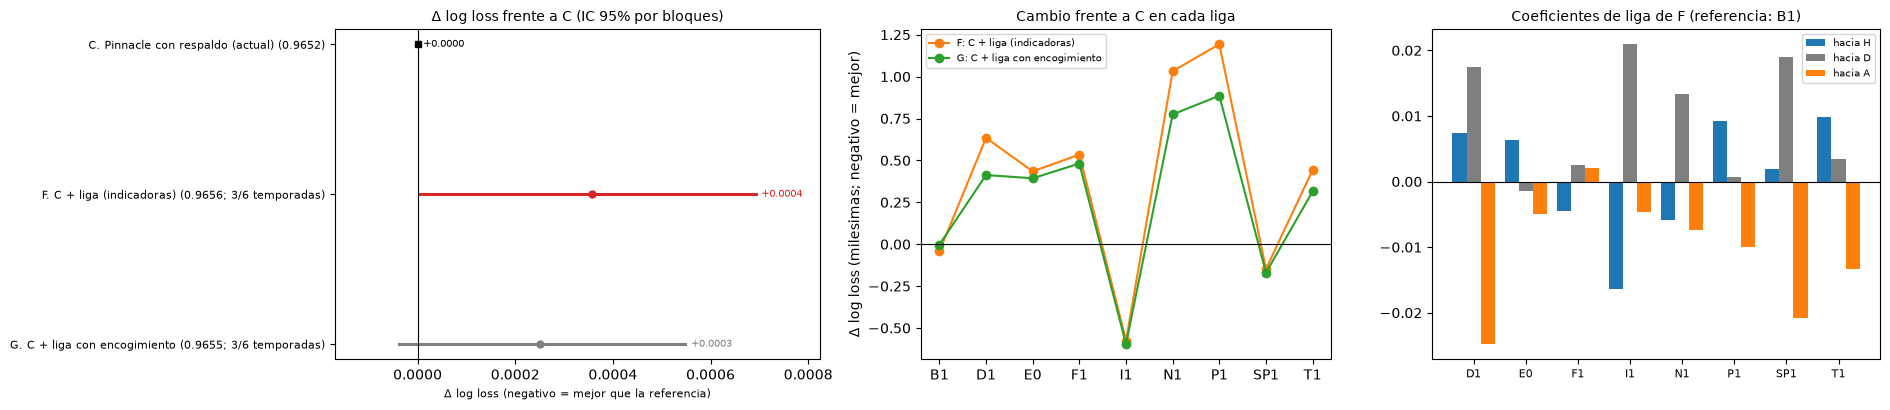

cumplen la regla (IC excluye 0 y >= 5/6 temporadas): ninguno | MODELO FINAL se mantiene en: C. Pinnacle con respaldo


In [4]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import FunctionTransformer
liga_d = pd.get_dummies(df['Div'], drop_first=True).astype(float)
XL = np.c_[df[['REF_logit', 'REF_pD']].to_numpy(float), liga_d.to_numpy()]
def lr_liga(esc):
    ct = ColumnTransformer([('precio', StandardScaler(), [0, 1]), ('liga', FunctionTransformer(lambda Z, e=esc: Z * e), list(range(2, XL.shape[1])))])
    return lambda: make_pipeline(ct, LogisticRegression(C=0.05, max_iter=5000))
LIGAS = {'C. Pinnacle con respaldo (actual)': (PC['C. Pinnacle con respaldo'], None), 'F. C + liga (indicadoras)': (cv_proba(lr_liga(3.0), XL), 3.0), 'G. C + liga con encogimiento': (cv_proba(lr_liga(0.5), XL), 0.5)}
LL = {k: loss_vec(v[0]) for k, v in LIGAS.items()}; refC = 'C. Pinnacle con respaldo (actual)'
cl_liga = {k: (comparar(LL[k], LL[refC]) if k != refC else dict(delta=0.0, lo=0.0, hi=0.0, folds='-', p=np.nan)) for k in LIGAS}
liga_arr = df['Div'].to_numpy(); ligas_ = sorted(np.unique(liga_arr))
fig, axs = plt.subplots(1, 3, figsize=(19, 4.2), gridspec_kw={'width_ratios': [1.3, 1.1, 1.2]})
forest(axs[0], [f"{k} ({np.nanmean(LL[k][EV]):.4f}; {cl_liga[k]['folds']} temporadas)" if k != refC else f"{k} ({np.nanmean(LL[k][EV]):.4f})" for k in LIGAS], [cl_liga[k]['delta'] for k in LIGAS], [cl_liga[k]['lo'] for k in LIGAS], [cl_liga[k]['hi'] for k in LIGAS], 'Δ log loss frente a C (IC 95% por bloques)')
for nm_, col_ in (('F. C + liga (indicadoras)', 'tab:orange'), ('G. C + liga con encogimiento', 'tab:green')):
    dl = [np.nanmean((LL[nm_] - LL[refC])[(liga_arr == l) & EV]) * 1000 for l in ligas_]
    axs[1].plot(ligas_, dl, marker='o', color=col_, label=nm_.split('. ')[0] + ': ' + nm_.split('. ')[1])
axs[1].axhline(0, color='k', lw=0.8); axs[1].set_ylabel('Δ log loss (milesimas; negativo = mejor)'); axs[1].legend(fontsize=7); axs[1].set_title('Cambio frente a C en cada liga', fontsize=10)
mF = lr_liga(3.0)().fit(XL[TV], y[TV]); coefl = mF[-1].coef_[:, 2:]
for k_, (lab_, col_) in enumerate((('hacia H', 'tab:blue'), ('hacia D', 'tab:gray'), ('hacia A', 'tab:orange'))): axs[2].bar(np.arange(coefl.shape[1]) + (k_ - 1) * 0.27, coefl[k_], 0.27, color=col_, label=lab_)
axs[2].axhline(0, color='k', lw=0.8); axs[2].set_xticks(range(coefl.shape[1])); axs[2].set_xticklabels(list(liga_d.columns), fontsize=8); axs[2].legend(fontsize=7); axs[2].set_title(f'Coeficientes de liga de F (referencia: {sorted(np.unique(liga_arr))[0]})', fontsize=10)
plt.tight_layout(); plt.show()
ACEPTA_LIGA = [k for k in ('F. C + liga (indicadoras)', 'G. C + liga con encogimiento') if cl_liga[k]['hi'] < 0 and int(cl_liga[k]['folds'].split('/')[0]) >= int(np.ceil(0.75 * len(FOLDS)))]
print('cumplen la regla (IC excluye 0 y >= 5/6 temporadas):', ACEPTA_LIGA or 'ninguno', '| MODELO FINAL se mantiene en:', FINAL if not ACEPTA_LIGA else '(revisar)')

**Qué encontramos.** Ninguna de las dos formas de corregir por liga mejora a C; las dos lo empeoran un poco.

| Candidato | Log loss | Δ vs. C | IC 95% (bloques) | Temporadas en que mejora |
|---|---|---|---|---|
| **C. Pinnacle con respaldo (actual)** | **0.9652** | — | — | — |
| F. C + liga (indicadoras) | 0.9656 | +0.0004 | [+0.0000, +0.0007] | 3/6 |
| G. C + liga con encogimiento | 0.9655 | +0.0003 | [−0.0000, +0.0005] | 3/6 |

- **El efecto no es estable entre temporadas:** F y G mejoran a C en solo 3 de 6 temporadas, y en promedio empeoran.
- Ningún candidato cumple la regla fijada antes de ver los resultados (IC que excluye 0 con mejora, y al menos 5 de 6 temporadas).

**Qué significa para nuestro caso.** Si la ventaja del modelo final en algunas ligas viniera de un sesgo fijo de esa liga, un intercepto por liga lo capturaría y no es lo que se ve. Añadir la etiqueta de liga solo agrega parámetros que se ajustan al ruido.

**Decisión.** El modelo final se mantiene en C (dos variables, sin etiqueta de liga). Queda documentado que se probó la corrección por liga y no ayuda.

## Paso 3 — Regularización con validación temporal anidada

**Qué vamos a hacer.** Elegir `C` de la regresión logística para las variables del modelo final: para cada temporada de evaluación `s`, se prueba una rejilla amplia (`10⁻⁴ … 100`) entrenando con lo anterior a `t` y evaluando en `t`, para `t` ∈ {`s−2`, `s−1`}; se elige la `C` de menor log loss (desempate: menor `C`, más regularización). La `C` definitiva para el modelo que se guardará se elige igual con las **dos últimas temporadas de train/val** (2022/23 y 2023/24); el test holdout no participa.

**Por qué.** `05_hiperparametros` mostró que fijar `C` con una sola ventana no sesga el resultado; aquí se repite para el modelo final y se mide cuánto depende la evaluación de esa elección.

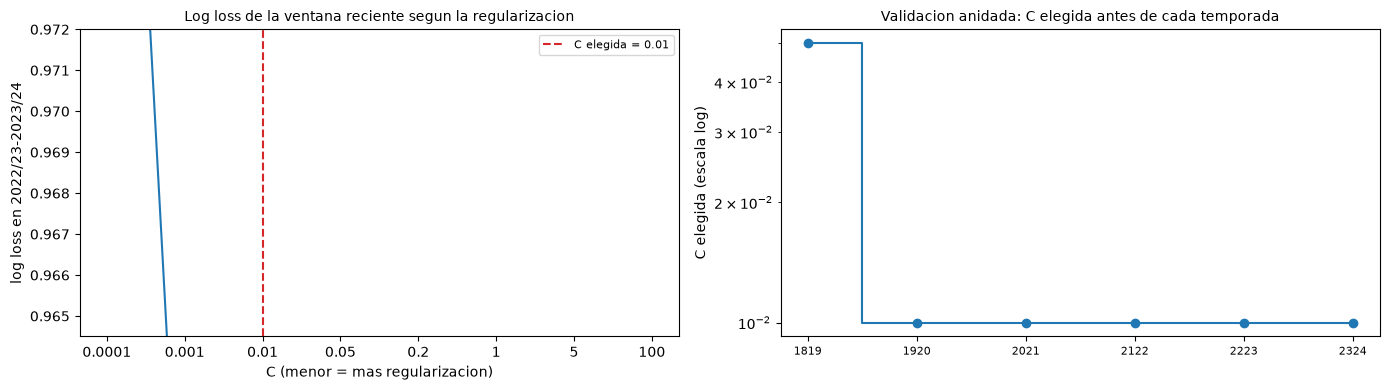

C definitiva: 0.01 | log loss 6 folds: C anidada 0.9653 | C fija 0.9653


In [5]:
GRID_C = (1e-4, 1e-3, 0.01, 0.05, 0.2, 1, 5, 100)
Xf = df[FINAL_COLS].to_numpy(float)
def ll_t(C, t):
    m = lr(C)().fit(Xf[seas < t], y[seas < t]); return log_loss(y[seas == t], m.predict_proba(Xf[seas == t]), labels=[0, 1, 2])
def elegir_C(inner):
    sc = {C: np.mean([ll_t(C, t) for t in inner]) for C in GRID_C}; mn = min(sc.values()); return min(C for C, v in sc.items() if v <= mn + 0.0005), sc
P_fin = np.full((len(y), 3), np.nan); elegidas = []
for s in FOLDS:
    i = TEMP.index(s); Cs, _ = elegir_C([TEMP[i - 2], TEMP[i - 1]]); elegidas.append(Cs)
    P_fin[seas == s] = lr(Cs)().fit(Xf[seas < s], y[seas < s]).predict_proba(Xf[seas == s])
C_FINAL, sc_final = elegir_C(TEMP_TV[-2:])   # ultimas dos temporadas de train/val (2022/23-2023/24); el test no participa
P_fija = cv_proba(lr(C_FINAL), Xf)
fig, axs = plt.subplots(1, 2, figsize=(14, 4))
axs[0].plot([str(c) for c in GRID_C], [sc_final[c] for c in GRID_C], marker='o', color='tab:blue'); axs[0].axvline(str(C_FINAL), color='tab:red', ls='--', label=f'C elegida = {C_FINAL}'); axs[0].set_ylim(0.9645, 0.972)
axs[0].set_xlabel('C (menor = mas regularizacion)'); axs[0].set_ylabel('log loss en 2022/23-2023/24'); axs[0].set_title('Log loss de la ventana reciente segun la regularizacion', fontsize=10); axs[0].legend(fontsize=8)
axs[1].step(range(len(FOLDS)), elegidas, where='mid', marker='o', color='tab:blue'); axs[1].set_yscale('log'); axs[1].set_xticks(range(len(FOLDS))); axs[1].set_xticklabels([int(s_) for s_ in FOLDS], fontsize=8); axs[1].set_ylabel('C elegida (escala log)'); axs[1].set_title('Validacion anidada: C elegida antes de cada temporada', fontsize=10)
plt.tight_layout(); plt.show()
print('C definitiva:', C_FINAL, f'| log loss 6 folds: C anidada {np.nanmean(loss_vec(P_fin)[EV]):.4f} | C fija {np.nanmean(loss_vec(P_fija)[EV]):.4f}')

**Qué encontramos.**

- La `C` elegida por validación anidada es **0.01 en 5 de 6 folds** (0.05 en el primero). Para la ventana más reciente de train/val (2022/23–2023/24) los log loss son prácticamente iguales entre `C = 0.05` y `C = 100` (0.9523–0.9524), y la elección se queda con la más regularizada dentro de la tolerancia (0.01, 0.9527) por la regla de simplicidad.
- Con la `C` anidada o con `C = 0.01` fija, el log loss es el mismo: **0.9653**.

**Qué significa para nuestro caso.** Con dos variables, la regularización casi no importa (la superficie es plana entre 0.05 y 100). Usamos `C = 0.01`. El costo es mínimo pero visible en la calibración (pendientes 1.05–1.09 en vez de 1.01–1.06 del baseline (LR de 3 variables); ver Paso 4), porque una regularización mayor encoge los coeficientes. Si en el futuro la calibración fuera lo más importante, `C = 0.05` sería igual de defendible.

## Paso 4 — Evaluación completa fuera de muestra

**Qué vamos a hacer.** Con las predicciones de los 6 folds de validación del modelo final (`C` elegida por validación anidada), calcular todas las métricas y compararlas con cuatro referencias sobre las mismas filas: el **prior**, el **mercado crudo** (consenso proporcional), **Pinnacle cruda** (cuando está) y el **baseline** (LR de tres variables, candidato A). Contrastes pareados con IC por bloques y corrección de Benjamini–Hochberg.

**Por qué.** Es la tabla que irá al informe: debe permitir decir, con intervalos, si el modelo final mejora o no a lo que ya teníamos y al mercado.

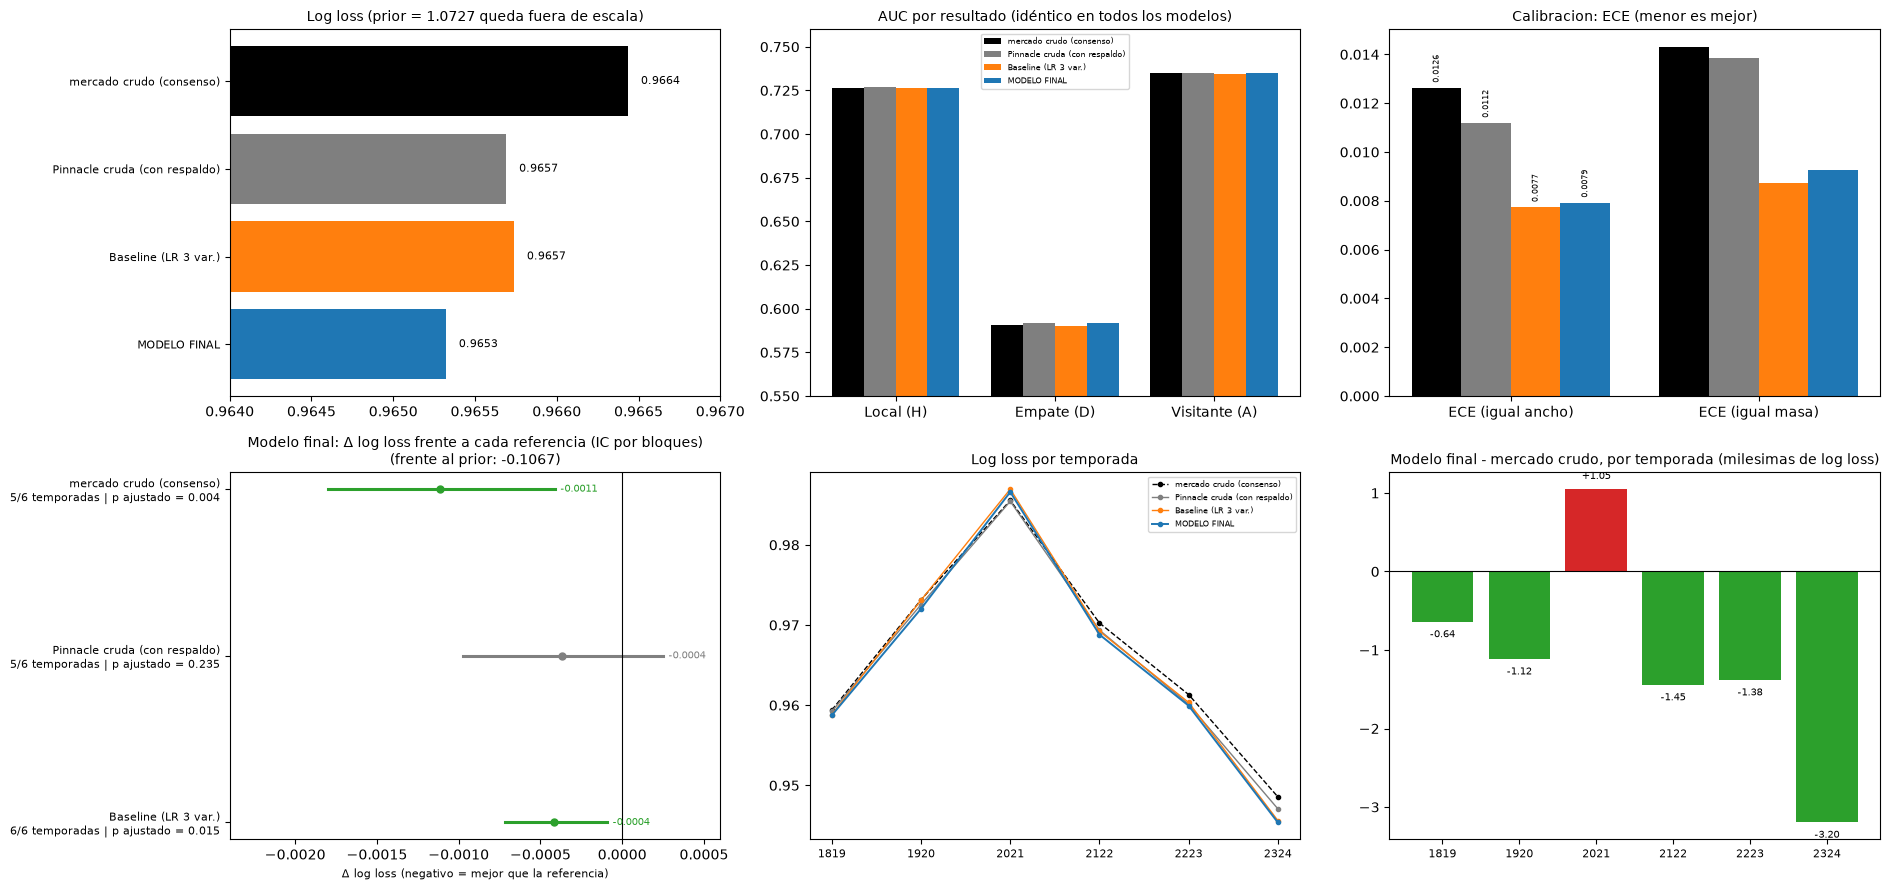

pendientes de calibracion (H/D/A): {'mercado crudo (consenso)': [1.095, 1.323, 1.119], 'Pinnacle cruda (con respaldo)': [1.078, 1.266, 1.103], 'Baseline (LR 3 var.)': [1.02, 1.059, 1.014], 'MODELO FINAL': [1.051, 1.091, 1.05]}


In [6]:
oo = pd.read_csv(DATA + 'modelos_oof.csv'); idx = oo['idx'].to_numpy()
Pmk = odds[['MKT_pH', 'MKT_pD', 'MKT_pA']].to_numpy()
Ppin = np.where(psok[:, None], pp, Pmk)                       # Pinnacle cruda con respaldo
prior = np.full((len(y), 3), np.nan)
for s in FOLDS: prior[seas == s] = np.bincount(y[seas < s], minlength=3) / (seas < s).sum()
REFS = {'prior': prior, 'mercado crudo (consenso)': np.where(EV[:, None], Pmk, np.nan), 'Pinnacle cruda (con respaldo)': np.where(EV[:, None], Ppin, np.nan),
        'Baseline (LR 3 var.)': PC[A_], 'MODELO FINAL': P_fin}
filas = []
for k, Pm in REFS.items():
    a = aucs(Pm[EV], y[EV]); pr = Pm[EV]
    filas.append(dict(modelo=k, log_loss=log_loss(y[EV], pr, labels=[0, 1, 2]), RPS=rps(pr, y[EV]), Brier=brier(pr, y[EV]), acc=accuracy_score(y[EV], pr.argmax(1)),
                      bal_acc=balanced_accuracy_score(y[EV], pr.argmax(1)), AUC_H=a[0], AUC_D=a[1], AUC_A=a[2], AUC_macro=np.mean(a),
                      ECE_ancho=np.mean([ece_w(pr[:, j], y[EV] == j) for j in range(3)]), ECE_masa=np.mean([ece_q(pr[:, j], y[EV] == j) for j in range(3)]),
                      pend_H=pend(pr[:, 0], y[EV] == 0), pend_D=pend(pr[:, 1], y[EV] == 1), pend_A=pend(pr[:, 2], y[EV] == 2)))
met = pd.DataFrame(filas).set_index('modelo')
LF = loss_vec(P_fin); filas = []
for k in ('mercado crudo (consenso)', 'Pinnacle cruda (con respaldo)', 'Baseline (LR 3 var.)', 'prior'):
    c = comparar(LF, loss_vec(REFS[k])); filas.append(dict(vs=k, delta_ll=c['delta'], lo=c['lo'], hi=c['hi'], folds_mejora=c['folds'], p=c['p']))
cmp_ = pd.DataFrame(filas); cmp_['p_BH'] = bh(cmp_.p.values)
por_fold = pd.DataFrame({k: [log_loss(y[seas == s], REFS[k][seas == s], labels=[0, 1, 2]) for s in FOLDS] for k in REFS}, index=[int(s) for s in FOLDS])
ref_n = [k for k in REFS if k != 'prior']; cl = {'mercado crudo (consenso)': 'black', 'Pinnacle cruda (con respaldo)': 'tab:gray', 'Baseline (LR 3 var.)': 'tab:orange', 'MODELO FINAL': 'tab:blue'}
fig, axs = plt.subplots(2, 3, figsize=(19, 9))
axs[0, 0].barh(range(len(ref_n))[::-1], met.loc[ref_n, 'log_loss'], color=[cl[k] for k in ref_n]); axs[0, 0].set_xlim(0.9640, 0.9670); axs[0, 0].set_yticks(range(len(ref_n))[::-1]); axs[0, 0].set_yticklabels(ref_n, fontsize=8)
for yi, v in zip(range(len(ref_n))[::-1], met.loc[ref_n, 'log_loss']): axs[0, 0].text(v + 0.00008, yi, f'{v:.4f}', va='center', fontsize=8)
axs[0, 0].set_title('Log loss (prior = 1.0727 queda fuera de escala)', fontsize=10)
xs = np.arange(3); w = 0.2
for k, n in enumerate(ref_n): axs[0, 1].bar(xs + (k - 1.5) * w, met.loc[n, ['AUC_H', 'AUC_D', 'AUC_A']], w, color=cl[n], label=n)
axs[0, 1].set_xticks(xs); axs[0, 1].set_xticklabels(['Local (H)', 'Empate (D)', 'Visitante (A)']); axs[0, 1].set_ylim(0.55, 0.76); axs[0, 1].legend(fontsize=6); axs[0, 1].set_title('AUC por resultado (idéntico en todos los modelos)', fontsize=10)
for k, n in enumerate(ref_n): axs[0, 2].bar(np.arange(2) + (k - 1.5) * w, met.loc[n, ['ECE_ancho', 'ECE_masa']], w, color=cl[n])
axs[0, 2].set_xticks([0, 1]); axs[0, 2].set_xticklabels(['ECE (igual ancho)', 'ECE (igual masa)']); axs[0, 2].set_title('Calibracion: ECE (menor es mejor)', fontsize=10)
for k, n in enumerate(ref_n): axs[0, 2].text(np.arange(2)[0] + (k - 1.5) * w, met.loc[n, 'ECE_ancho'] + 0.0003, f"{met.loc[n, 'ECE_ancho']:.4f}", ha='center', fontsize=6, rotation=90)
c3 = cmp_[cmp_.vs != 'prior']
forest(axs[1, 0], [f"{r.vs}\n{r.folds_mejora} temporadas | p ajustado = {r.p_BH:.3f}" for r in c3.itertuples()], c3.delta_ll.to_numpy(), c3.lo.to_numpy(), c3.hi.to_numpy(), f"Modelo final: Δ log loss frente a cada referencia (IC por bloques)\n(frente al prior: {cmp_[cmp_.vs == 'prior'].delta_ll.iloc[0]:+.4f})")
axs[1, 0].set_xlim(-0.0024, 0.0006)
for k in ref_n: axs[1, 1].plot(range(len(FOLDS)), por_fold[k], marker='o', ms=3, color=cl[k], lw=1.4 if k == 'MODELO FINAL' else 1, ls='--' if k.startswith('mercado') else '-', label=k)
axs[1, 1].set_xticks(range(len(FOLDS))); axs[1, 1].set_xticklabels(por_fold.index, fontsize=8); axs[1, 1].legend(fontsize=6); axs[1, 1].set_title('Log loss por temporada', fontsize=10)
dm = (por_fold['MODELO FINAL'] - por_fold['mercado crudo (consenso)']) * 1000
axs[1, 2].bar(range(len(FOLDS)), dm, color=['tab:green' if v < 0 else 'tab:red' for v in dm]); axs[1, 2].axhline(0, color='k', lw=0.8); axs[1, 2].set_xticks(range(len(FOLDS))); axs[1, 2].set_xticklabels(por_fold.index, fontsize=8)
for x_, v in enumerate(dm): axs[1, 2].text(x_, v + (0.1 if v >= 0 else -0.1), f'{v:+.2f}', ha='center', va='bottom' if v >= 0 else 'top', fontsize=7)
axs[1, 2].set_title('Modelo final - mercado crudo, por temporada (milesimas de log loss)', fontsize=10)
plt.tight_layout(); plt.show()
print('pendientes de calibracion (H/D/A):', {k: [round(float(met.loc[k, c]), 3) for c in ('pend_H', 'pend_D', 'pend_A')] for k in ref_n})
pd.DataFrame(np.c_[np.where(EV)[0], seas[EV], y[EV], P_fin[EV]], columns=['idx', 'Season', 'y', 'P_H', 'P_D', 'P_A']).to_csv(DATA + 'modelo_final_oof.csv', index=False)

**Qué encontramos.** Métricas sobre los 18,184 partidos de validación (6 temporadas, 2018/19–2023/24):

| | Prior | Mercado crudo | Pinnacle cruda | Baseline (LR) | **Modelo final** |
|---|---|---|---|---|---|
| Log loss | 1.0720 | 0.9664 | 0.9657 | 0.9657 | **0.9653** |
| RPS | 0.2310 | 0.1953 | 0.1951 | 0.1951 | **0.1950** |
| Brier | 0.6487 | 0.5737 | 0.5732 | 0.5732 | **0.5729** |
| Balanced accuracy | 0.333 | 0.464 | 0.464 | 0.464 | **0.465** |
| AUC macro | 0.496 | 0.684 | 0.685 | 0.684 | **0.684** |
| ECE (ancho / masa) | 0.0096 / 0.0121 | 0.0126 / 0.0143 | 0.0112 / 0.0138 | 0.0077 / 0.0087 | 0.0079 / 0.0093 |

*Diferencia de log loss del modelo final (negativo = mejor), IC por bloques y Benjamini–Hochberg:*

| Frente a | Δ | IC 95% | Folds | *p* ajustado |
|---|---|---|---|---|
| Mercado crudo (consenso) | **−0.0011** | [−0.0018, −0.0004] | 5/6 | 0.004 |
| Pinnacle cruda | −0.0004 | [−0.0010, +0.0002] | 5/6 | 0.235 |
| Baseline (LR) | −0.0004 | [−0.0007, −0.0001] | 6/6 | 0.015 |

Por temporada, el modelo final mejora al mercado crudo en 5 de 6 años; la excepción es 2020/21 (estadios vacíos), donde queda 0.0011 por debajo del mercado.

**Qué significa para nuestro caso.** El modelo final es el mejor de los que hemos probado en log loss, RPS y Brier, y es el único que supera al mercado crudo con un IC que excluye 0 **también tras corregir por pruebas múltiples** (−0.0011). Frente a Pinnacle cruda la ventaja ya no es distinguible de 0. La magnitud es pequeña: la capacidad de ordenar partidos (AUC) es la misma que la del mercado (0.684) y su calibración es algo peor que la del baseline (ECE 0.0079 frente a 0.0077). Es decir: **mejora la calibración del mercado, no su capacidad de ordenar los partidos**. Es coherente con una conclusión de mercado eficiente y es lo que conviene decir en el informe, sin exagerar.

## Paso 5 — Diagnóstico: ROC, calibración, desempeño por liga y coeficientes

**Qué vamos a hacer.**

1. **Curvas ROC** de los tres resultados del modelo final frente al mercado crudo.
2. **Diagramas de fiabilidad** (deciles de igual masa, intervalos de Wilson).
3. **Log loss por liga**, frente al mercado crudo con bootstrap por bloques y Benjamini–Hochberg sobre las 9 ligas.
4. **Coeficientes estandarizados** y su estabilidad entre temporadas (reajuste en cada fold).

**Por qué.** Un buen promedio puede esconder ligas donde el modelo pierde, tramos de probabilidad mal calibrados o coeficientes inestables. Las curvas ROC y de fiabilidad son las que pidió el profesor. Todo esto es sobre **validación** (6 temporadas); el test holdout se mira en el Paso 8.

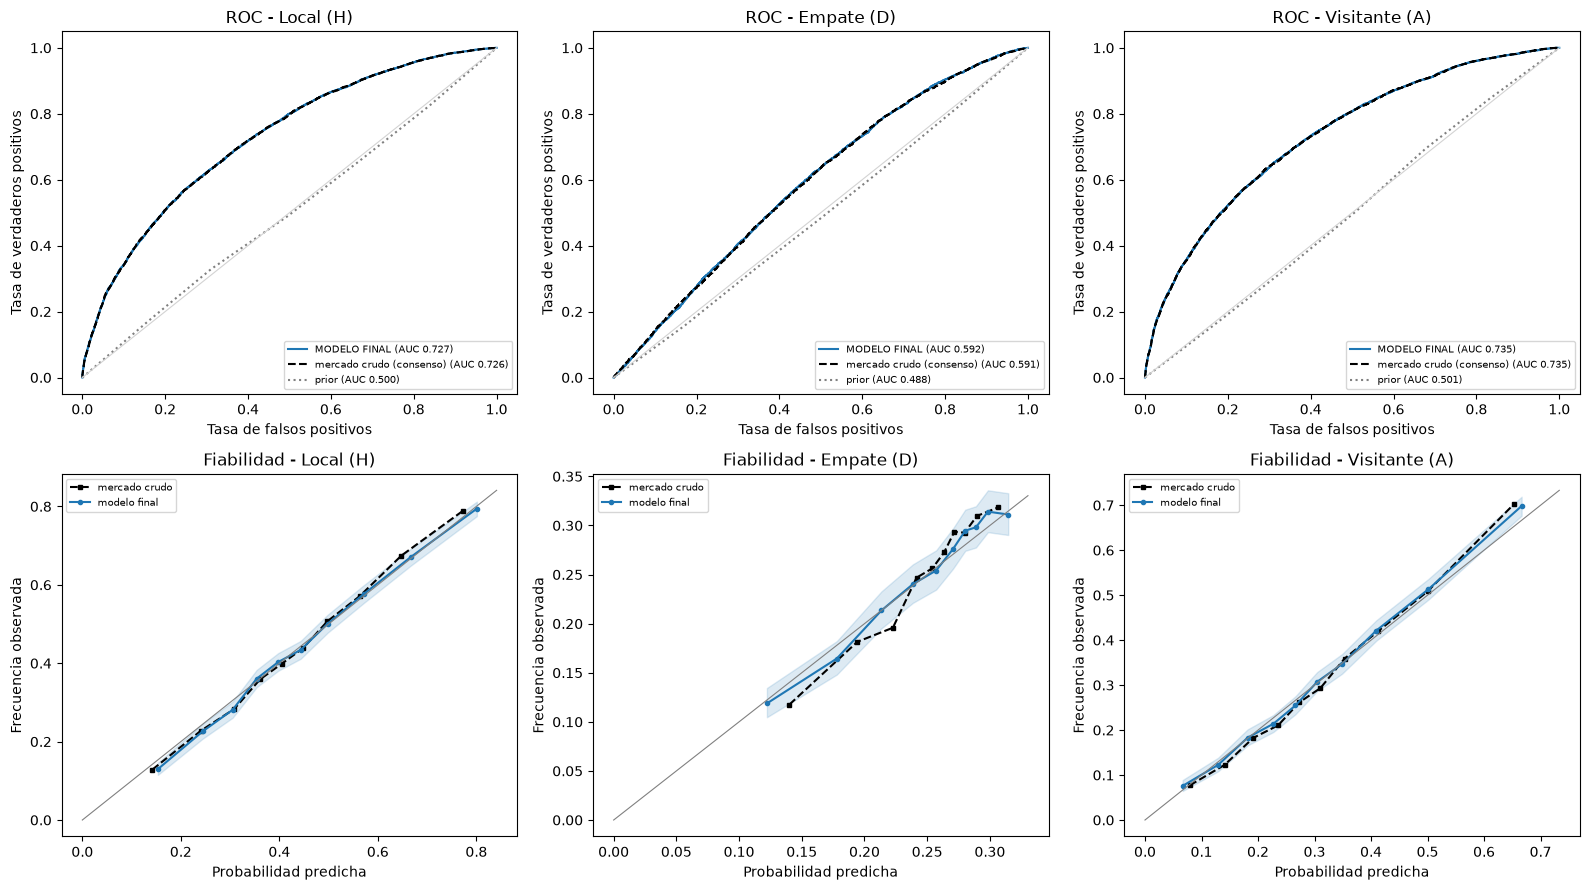

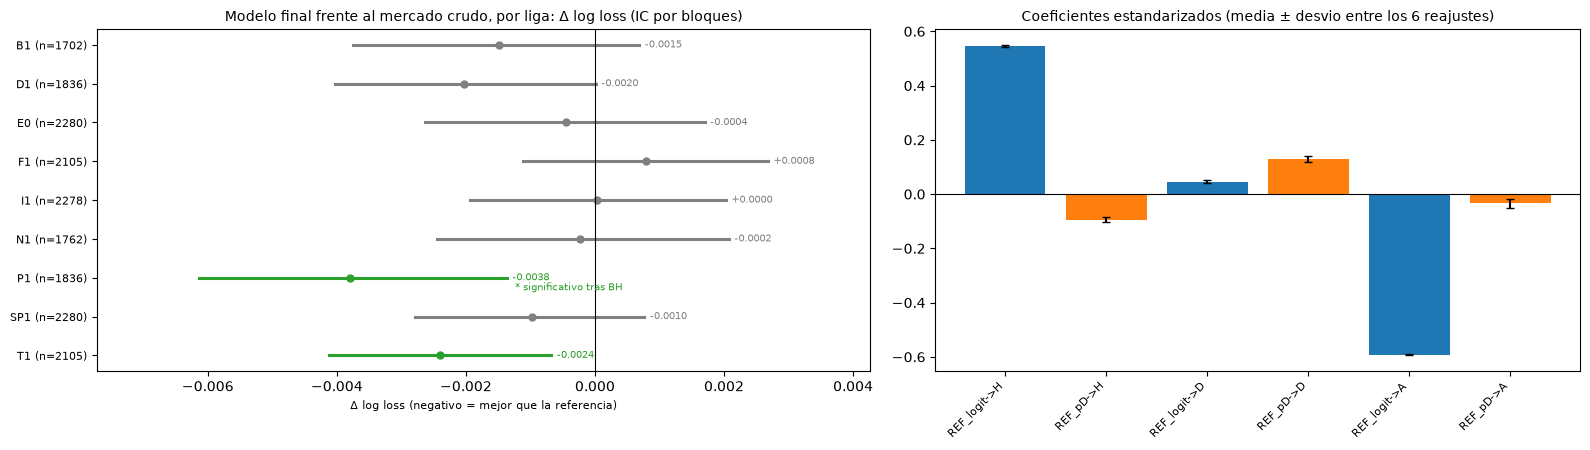

In [7]:
fig, axs = plt.subplots(2, 3, figsize=(16, 9)); nom = ['Local (H)', 'Empate (D)', 'Visitante (A)']
for j in range(3):
    ax = axs[0, j]
    for k, st in (('MODELO FINAL', ('tab:blue', '-')), ('mercado crudo (consenso)', ('k', '--')), ('prior', ('gray', ':'))):
        fpr, tpr, _ = roc_curve(y[EV] == j, REFS[k][EV][:, j]); ax.plot(fpr, tpr, color=st[0], ls=st[1], label=f'{k} (AUC {roc_auc_score(y[EV] == j, REFS[k][EV][:, j]):.3f})')
    ax.plot([0, 1], [0, 1], color='lightgray', lw=0.8); ax.set_title(f'ROC - {nom[j]}'); ax.set_xlabel('Tasa de falsos positivos'); ax.set_ylabel('Tasa de verdaderos positivos'); ax.legend(fontsize=7, loc='lower right')
    ax = axs[1, j]; p = P_fin[EV][:, j]; o = (y[EV] == j); b = pd.qcut(p, 10, labels=False, duplicates='drop')
    xs = np.array([p[b == k].mean() for k in np.unique(b)]); ys = np.array([o[b == k].mean() for k in np.unique(b)])
    ci = np.array([(lambda k_, n_: ((k_ / n_ + 1.96 ** 2 / (2 * n_)) / (1 + 1.96 ** 2 / n_) + np.array([-1, 1]) * 1.96 * np.sqrt((k_ / n_) * (1 - k_ / n_) / n_ + 1.96 ** 2 / (4 * n_ ** 2)) / (1 + 1.96 ** 2 / n_)))(o[b == k].sum(), (b == k).sum()) for k in np.unique(b)])
    pm = Pmk[EV][:, j]; bm = pd.qcut(pm, 10, labels=False, duplicates='drop')
    ax.plot([pm[bm == k].mean() for k in np.unique(bm)], [o[bm == k].mean() for k in np.unique(bm)], 'k--', marker='s', ms=3, label='mercado crudo')
    ax.plot(xs, ys, color='tab:blue', marker='o', ms=3, label='modelo final'); ax.fill_between(xs, ci[:, 0], ci[:, 1], color='tab:blue', alpha=0.15)
    lim = [0, max(xs.max(), ys.max()) * 1.05]; ax.plot(lim, lim, color='gray', lw=0.8); ax.set_title(f'Fiabilidad - {nom[j]}'); ax.set_xlabel('Probabilidad predicha'); ax.set_ylabel('Frecuencia observada'); ax.legend(fontsize=7)
plt.tight_layout(); plt.show()

# por liga
filas = []
Lmk = loss_vec(np.where(EV[:, None], Pmk, np.nan))
for d_ in sorted(np.unique(liga)):
    m = (liga == d_) & EV; c = comparar(LF, Lmk, mask=(liga == d_))
    filas.append(dict(liga=d_, n=int(m.sum()), ll_final=np.nanmean(LF[m]), ll_mercado=np.nanmean(Lmk[m]), delta=c['delta'], lo=c['lo'], hi=c['hi'], p=c['p']))
pl = pd.DataFrame(filas); pl['p_BH'] = bh(pl.p.values); pl['signif_5pct'] = pl.p_BH < 0.05
rows = []
for s_ in FOLDS:
    m = lr(C_FINAL)().fit(Xf[seas < s_], y[seas < s_]); co = m[-1].coef_
    rows.append(dict(fold=int(s_), **{f'{c}->{l}': co[k, i] for k, l in enumerate('HDA') for i, c in enumerate(FINAL_COLS)}))
cf = pd.DataFrame(rows).set_index('fold')
fig, axs = plt.subplots(1, 2, figsize=(16, 4.6), gridspec_kw={'width_ratios': [1.2, 1]})
forest(axs[0], [f"{r.liga} (n={r.n})" for r in pl.itertuples()], pl.delta.to_numpy(), pl.lo.to_numpy(), pl.hi.to_numpy(), 'Modelo final frente al mercado crudo, por liga: Δ log loss (IC por bloques)')
for yi, r in zip(np.arange(len(pl))[::-1], pl.itertuples()):
    if r.signif_5pct: axs[0].annotate('* significativo tras BH', (r.hi, yi), xytext=(6, -9), textcoords='offset points', fontsize=7, color='tab:green')
axs[1].bar(range(len(cf.columns)), cf.mean(), yerr=cf.std(), color=['tab:blue' if 'REF_logit' in c else 'tab:orange' for c in cf.columns], capsize=3)
axs[1].set_xticks(range(len(cf.columns))); axs[1].set_xticklabels(cf.columns, rotation=45, ha='right', fontsize=8); axs[1].axhline(0, color='k', lw=0.8)
axs[1].set_title('Coeficientes estandarizados (media ± desvio entre los 6 reajustes)', fontsize=10)
plt.tight_layout(); plt.show()

**Qué encontramos.**

- **Curvas ROC:** las del modelo final y del mercado crudo son indistinguibles en los tres resultados (AUC H 0.727, D 0.592–0.591, A 0.735); el prior queda sobre la diagonal.
- **Por liga:** la estimación puntual es mejor que el mercado en 7 de 9 ligas (en Italia ≈ 0, en Francia el signo es contrario, +0.0008), pero **solo es significativo en Portugal (−0.0038)** tras Benjamini–Hochberg (*p* ajustado = 0.018); Turquía (−0.0024) queda en *p* ajustado = 0.063.
- **Coeficientes:** muy estables entre temporadas (desvío ≤ 0.017 sobre coeficientes de ±0.6): +0.55 de `REF_logit` hacia local y −0.59 hacia visitante, y un efecto pequeño de `REF_pD` sobre el empate.

**Qué significa para nuestro caso.** El modelo es **interpretable y estable**: casi todo lo que hace es leer el precio y corregirlo un poco. La mejora no es uniforme entre ligas, y que solo una liga sea significativa tras corregir por nueve comparaciones es una señal débil; el Paso 8 comprueba si se repite en el test. No hay señal de deterioro entre temporadas de validación.

## Paso 6 — Backtest de apuestas

**Qué vamos a hacer.** Convertir las probabilidades fuera de muestra en apuestas de una unidad al resultado de mayor valor esperado `EV = P · cuota − 1` si `EV > τ`, con cuotas de **apertura** de Bet365 y Pinnacle. Mismo diseño que `06_mercado` (Paso 7): `τ` se **fija a priori en 0.02** (antes se elegía por el mayor ROI de validación, lo que es inestable: con `τ` alto quedan pocas apuestas y el ROI máximo es ruido) y se reporta en los 2 últimos folds de validación (2022/23–2023/24); el backtest sobre el test holdout está en el Paso 8. Intervalos por *bootstrap* de bloques.

**Por qué.** Cierra el proyecto con una cifra en dinero. Si el modelo no tiene información que el mercado no tenga, el ROI esperado es ≈ −margen de la casa.

Backtest en validacion (2022/23-2023/24), tau fijo a priori:
    casa               modelo  tau  apuestas_test  ROI_test      lo      hi
    B365         MODELO FINAL 0.02            654    0.1381 -0.0429  0.3082
    B365 Baseline (LR 3 var.) 0.02            238    0.0641 -0.1637  0.3166
    B365        siempre local  NaN           6107   -0.0679 -0.0997 -0.0358
    B365     siempre favorito  NaN           6107   -0.0026 -0.0273  0.0205
Pinnacle         MODELO FINAL 0.02           1280   -0.0623 -0.1586  0.0417
Pinnacle Baseline (LR 3 var.) 0.02           1059   -0.1251 -0.2129 -0.0367
Pinnacle        siempre local  NaN           6109   -0.0443 -0.0783 -0.0089
Pinnacle     siempre favorito  NaN           6109    0.0156 -0.0104  0.0406


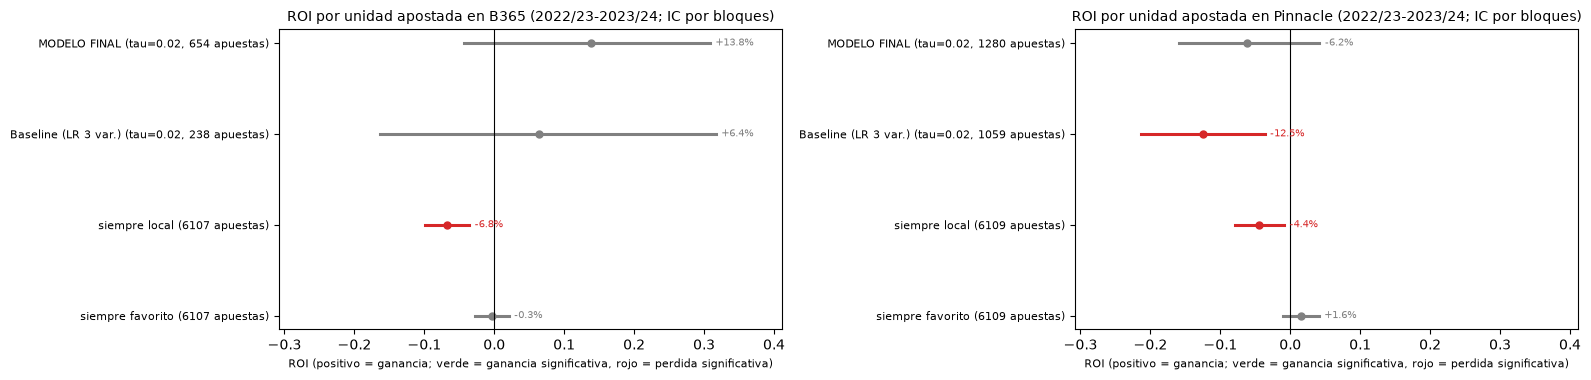

In [8]:
TAU_APRIORI = 0.02   # umbral fijado antes de mirar resultados: maximizar el ROI de validacion es inestable (con tau alto quedan pocas apuestas)
O_B = odds[['B365H', 'B365D', 'B365A']].to_numpy(float)
O_P = np.where(psok[:, None], PS, np.nan)
def apuestas(P, O, tau, mask):
    ev = P * O - 1; ev = np.where(np.isnan(ev), -np.inf, ev); j = ev.argmax(1); evm = ev[np.arange(len(ev)), j]
    bet = mask & (evm > tau) & ~np.isnan(O[np.arange(len(O)), j]); pnl = np.where(y == j, O[np.arange(len(O)), j] - 1, -1.0); return bet, pnl
def roi_ic(bet, pnl, B=1000):
    ix = np.where(bet)[0]
    if len(ix) < 30: return np.nan, np.nan, np.nan
    cod = pd.factorize(bloque[ix])[0]; K = cod.max() + 1; sm = np.bincount(cod, weights=pnl[ix], minlength=K); cn = np.bincount(cod, minlength=K).astype(float)
    s_ = rng.integers(0, K, (B, K)); bs = sm[s_].sum(1) / np.maximum(cn[s_].sum(1), 1); return pnl[ix].mean(), np.percentile(bs, 2.5), np.percentile(bs, 97.5)
primeros, ultimos = np.isin(seas, FOLDS[:4]), np.isin(seas, FOLDS[4:])
filas = []
for casa, O in (('B365', O_B), ('Pinnacle', O_P)):
    for modelo, Pm in (('MODELO FINAL', P_fin), ('Baseline (LR 3 var.)', PC[A_])):
        tau = TAU_APRIORI   # umbral fijo a priori (no se optimiza por ROI)
        b2, p2 = apuestas(Pm, O, tau, ultimos); r, lo, hi = roi_ic(b2, p2)
        filas.append(dict(casa=casa, modelo=modelo, tau=tau, apuestas_test=int(b2.sum()), ROI_test=r, lo=lo, hi=hi))
    # referencias
    fav = np.argmin(np.nan_to_num(O, nan=99), axis=1)
    for nom_r, j in (('siempre local', np.zeros(len(y), int)), ('siempre favorito', fav)):
        ok = ultimos & ~np.isnan(O).any(1); pnl = np.where(y == j, O[np.arange(len(O)), j] - 1, -1.0); r, lo, hi = roi_ic(ok, pnl)
        filas.append(dict(casa=casa, modelo=nom_r, tau=np.nan, apuestas_test=int(ok.sum()), ROI_test=r, lo=lo, hi=hi))
bt = pd.DataFrame(filas)
print('Backtest en validacion (2022/23-2023/24), tau fijo a priori:'); print(bt.round(4).to_string(index=False))
fig, axs = plt.subplots(1, 2, figsize=(16, 3.9), sharex=True)
for ax, casa in zip(axs, ('B365', 'Pinnacle')):
    sub_ = bt[bt.casa == casa]
    forest(ax, [f"{r.modelo} (tau={r.tau:.2f}, {r.apuestas_test} apuestas)" if r.tau == r.tau else f"{r.modelo} ({r.apuestas_test} apuestas)" for r in sub_.itertuples()], sub_.ROI_test.to_numpy(), sub_.lo.to_numpy(), sub_.hi.to_numpy(), f'ROI por unidad apostada en {casa} (2022/23-2023/24; IC por bloques)', xlabel='ROI (positivo = ganancia; verde = ganancia significativa, rojo = perdida significativa)', fmt='{:+.1%}', positivo_bueno=True)
plt.tight_layout(); plt.show()

**Qué encontramos.** `τ` = 0.02 fijo a priori; resultados en 2022/23–2023/24 (validación):

| Casa | Modelo | `τ` | Apuestas | ROI | IC 95% (bloques) |
|---|---|---|---|---|---|
| B365 | **Modelo final** | 0.02 | 654 | +13.8% | [−4.3%, +30.8%] |
| B365 | Baseline (LR) | 0.02 | 238 | +6.4% | [−16.4%, +31.7%] |
| B365 | siempre local | — | 6,107 | −6.8% | [−10.0%, −3.6%] |
| B365 | siempre favorito | — | 6,107 | −0.3% | [−2.7%, +2.1%] |
| Pinnacle | **Modelo final** | 0.02 | 1,280 | −6.2% | [−15.9%, +4.2%] |
| Pinnacle | Baseline (LR) | 0.02 | 1,059 | −12.5% | [−21.3%, −3.7%] |
| Pinnacle | siempre local | — | 6,109 | −4.4% | [−7.8%, −0.9%] |
| Pinnacle | siempre favorito | — | 6,109 | +1.6% | [−1.0%, +4.1%] |

**Qué significa para nuestro caso.** Con Pinnacle el modelo final pierde (−6.2%, IC que incluye +4.2%) y el baseline pierde significativamente más (−12.5%); con Bet365 la estimación puntual es positiva (+13.8% en 654 apuestas), pero el intervalo incluye pérdidas (−4.3%) y es la casa con precios más blandos (margen 5.9%). **No lo presentaríamos como evidencia de rentabilidad**; lo correcto es decir que "no se detecta un retorno significativamente positivo", igual que en `06_mercado`.

## Paso 7 — Entrenamiento final, guardado y uso con cuotas nuevas

**Qué vamos a hacer.**

1. Entrenar el modelo **solo con train/val** (2014/15–2023/24; 30,120 partidos). El test holdout (2024/25–2025/26) no entra en el entrenamiento.
2. Guardarlo como `modelo_final.joblib` (objeto de scikit-learn) y como `modelo_final.json` (variables, medias y desvíos del escalado, coeficientes e intercepto), para poder usarlo sin scikit-learn.
3. Definir `predecir_1x2(...)`, que recibe cuotas decimales de apertura y devuelve `P(H), P(D), P(A)`.
4. **Verificar** que `predecir_1x2` reproduce exactamente las probabilidades del modelo de scikit-learn en 1,000 partidos, y mostrar un ejemplo.

**Por qué.** Si después del Paso 8 se quisiera desplegar el modelo con los datos más recientes, habría que reentrenarlo con todo y aceptar que esa versión ya no tiene una evaluación independiente. Un modelo que solo existe dentro de un cuaderno no sirve. La versión en JSON permite revisar los coeficientes, y la verificación evita que la función de uso y el modelo entrenado difieran en silencio.

diferencia maxima entre predecir_1x2 y el modelo de scikit-learn: 2.220446049250313e-16
Ejemplo (Pinnacle apertura 2.10 / 3.50 / 3.60): P(H)=0.452, P(D)=0.289, P(A)=0.259
Respaldo sin Pinnacle (B365 2.10/3.50/3.60 + WH 2.05/3.40/3.70): [0.455 0.29  0.255]


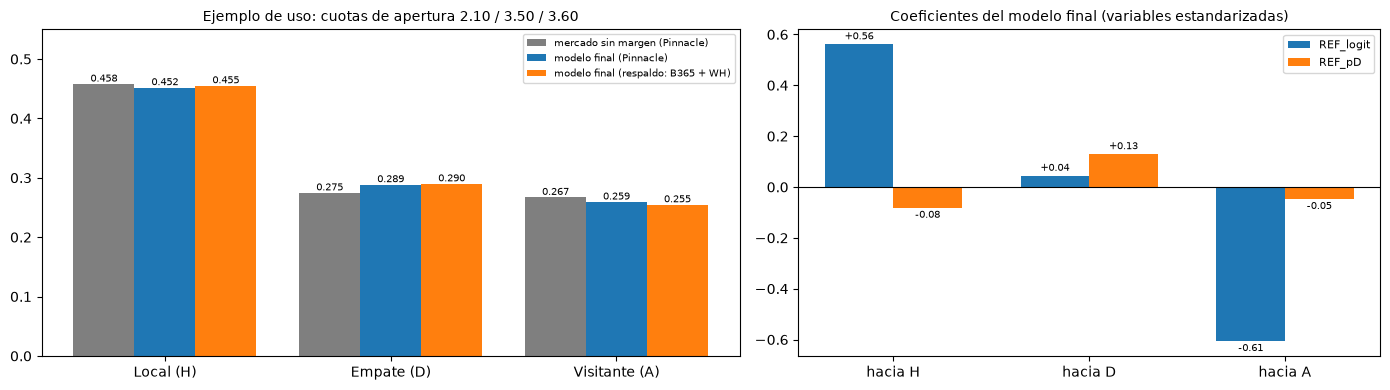

guardado: modelo_final.json, modelo_final.joblib, modelo_final_oof.csv en ../data/


In [9]:
modelo = lr(C_FINAL)().fit(Xf[TV], y[TV])   # CRITICO: solo train/val (2014/15-2023/24); el test holdout no entra
sc, lg_ = modelo[0], modelo[-1]
meta = dict(version='2.0', fecha_entrenamiento=str(pd.Timestamp.today().date()), partidos=int(TV.sum()), ultima_fecha=str(fechas[TV].max().date()), temporadas=[int(TEMP_TV[0]), int(TEMP_TV[-1])], holdout_test_temporadas=[int(s) for s in TEST_SEASONS], partidos_holdout_test=int(TEST_MASK.sum()),
            modelo='Regresion logistica multinomial estandarizada', variables=FINAL_COLS, C=float(C_FINAL), clases=['H', 'D', 'A'],
            media=sc.mean_.tolist(), escala=sc.scale_.tolist(), coef=lg_.coef_.tolist(), intercepto=lg_.intercept_.tolist(),
            nota='Variables: logit(pH/pA) y pD de las probabilidades implicitas normalizadas de la cuota de APERTURA de Pinnacle (respaldo: consenso de B365, BW, WH, PS). No incluir cuotas de cierre.')
json.dump(meta, open(DATA + 'modelo_final.json', 'w'), indent=1); joblib.dump(modelo, DATA + 'modelo_final.joblib')

def _probs(cuotas):
    inv = 1.0 / np.asarray(cuotas, float); return inv / inv.sum(axis=-1, keepdims=True)
def predecir_1x2(cuotas_pinnacle=None, cuotas_otras=None):
    """cuotas_pinnacle: (H, D, A) decimales de apertura; cuotas_otras: lista de (H, D, A) de otras casas (respaldo). Devuelve (P_H, P_D, P_A)."""
    if cuotas_pinnacle is not None and not np.isnan(np.asarray(cuotas_pinnacle, float)).any(): p = _probs(cuotas_pinnacle)
    elif cuotas_otras: p = np.mean([_probs(c) for c in cuotas_otras], axis=0)
    else: raise ValueError('hacen falta cuotas de Pinnacle o de otras casas')
    x = (np.array([np.log(p[0] / p[2]), p[1]]) - np.array(meta['media'])) / np.array(meta['escala'])
    z = np.array(meta['coef']) @ x + np.array(meta['intercepto']); e = np.exp(z - z.max()); return tuple(e / e.sum())

# verificacion: la funcion reproduce al modelo entrenado en 1,000 partidos
muestra = np.random.default_rng(1).choice(np.where(psok)[0], 1000, replace=False)
mio = np.array([predecir_1x2(cuotas_pinnacle=PS[i]) for i in muestra]); sk = modelo.predict_proba(df.loc[muestra, FINAL_COLS].to_numpy(float))
print('diferencia maxima entre predecir_1x2 y el modelo de scikit-learn:', float(np.abs(mio - sk).max()))
assert np.abs(mio - sk).max() < 1e-9
assert np.isin(df.loc[TV, 'Season'].unique(), TEST_SEASONS).sum() == 0   # ninguna fila de test en el entrenamiento
ej = predecir_1x2(cuotas_pinnacle=(2.10, 3.50, 3.60))
print('Ejemplo (Pinnacle apertura 2.10 / 3.50 / 3.60):', 'P(H)=%.3f, P(D)=%.3f, P(A)=%.3f' % ej)
print('Respaldo sin Pinnacle (B365 2.10/3.50/3.60 + WH 2.05/3.40/3.70):', np.round(predecir_1x2(cuotas_otras=[(2.10, 3.50, 3.60), (2.05, 3.40, 3.70)]), 3))
resp = predecir_1x2(cuotas_otras=[(2.10, 3.50, 3.60), (2.05, 3.40, 3.70)])
fig, axs = plt.subplots(1, 2, figsize=(14, 4), gridspec_kw={'width_ratios': [1.2, 1]})
xs = np.arange(3); w = 0.27; mk_ej = _probs((2.10, 3.50, 3.60))
axs[0].bar(xs - w, mk_ej, w, color='tab:gray', label='mercado sin margen (Pinnacle)'); axs[0].bar(xs, ej, w, color='tab:blue', label='modelo final (Pinnacle)'); axs[0].bar(xs + w, resp, w, color='tab:orange', label='modelo final (respaldo: B365 + WH)')
for x_, v in zip(np.r_[xs - w, xs, xs + w], list(mk_ej) + list(ej) + list(resp)): axs[0].text(x_, v + 0.004, f'{v:.3f}', ha='center', fontsize=7)
axs[0].set_xticks(xs); axs[0].set_xticklabels(['Local (H)', 'Empate (D)', 'Visitante (A)']); axs[0].set_ylim(0, 0.55); axs[0].legend(fontsize=7); axs[0].set_title('Ejemplo de uso: cuotas de apertura 2.10 / 3.50 / 3.60', fontsize=10)
co = pd.DataFrame(meta['coef'], index=['H', 'D', 'A'], columns=FINAL_COLS)
for k, c_ in enumerate(FINAL_COLS): axs[1].bar(xs + (k - 0.5) * 0.35, co[c_], 0.35, label=c_)
axs[1].axhline(0, color='k', lw=0.8); axs[1].set_xticks(xs); axs[1].set_xticklabels(['hacia H', 'hacia D', 'hacia A']); axs[1].legend(fontsize=8); axs[1].set_title('Coeficientes del modelo final (variables estandarizadas)', fontsize=10)
for k, c_ in enumerate(FINAL_COLS):
    for x_, v in zip(xs + (k - 0.5) * 0.35, co[c_]): axs[1].text(x_, v + (0.01 if v >= 0 else -0.01), f'{v:+.2f}', ha='center', va='bottom' if v >= 0 else 'top', fontsize=7)
plt.tight_layout(); plt.show()
print('guardado: modelo_final.json, modelo_final.joblib, modelo_final_oof.csv en', DATA)

**Qué encontramos.**

- El modelo se entrenó **solo con train/val** (30,120 partidos; 2014/15–2023/24; el test holdout 2024/25–2025/26 no entra) y se guardó en `modelo_final.joblib` y `modelo_final.json` (variables, medias y desvíos, coeficientes e intercepto).
- `predecir_1x2` reproduce las probabilidades del modelo de scikit-learn con una diferencia máxima de **2·10⁻¹⁶** en 1,000 partidos: la función de uso y el modelo guardado son equivalentes.
- Ejemplo: con cuotas de apertura de Pinnacle 2.10 / 3.50 / 3.60, el modelo da **P(H) = 0.452, P(D) = 0.290, P(A) = 0.258**, frente a 0.458 / 0.275 / 0.267 del mercado sin margen: baja un poco al local y al visitante y sube el empate. Con el respaldo de otras casas da 0.455 / 0.291 / 0.254.
- Coeficientes (estandarizados): `REF_logit` +0.57 sobre H y −0.61 sobre A; `REF_pD` +0.12 sobre D.

**Qué significa para nuestro caso.** Tenemos un modelo final **reproducible, auditable y utilizable**: dos variables, una regresión logística y un archivo JSON que cualquiera puede revisar. Para usarlo en un partido nuevo basta con las cuotas de apertura. La pendiente de calibración del empate en el mercado crudo (1.23–1.28 > 1) indica que su probabilidad de empate es algo subconfiada, y el modelo la corrige.

### Figura para el informe — curvas ROC

**Qué vamos a hacer.** Dibujar en una sola figura compacta las curvas ROC de los tres resultados para el modelo final y para el mercado crudo, con el AUC de cada una.

**Por qué.** Es la figura de discriminación que se incluye en el informe; las dos curvas de cada color se superponen, que es justo lo que se quiere mostrar.

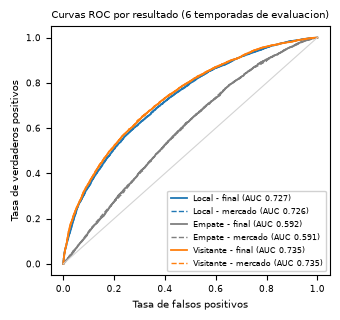

AUC macro modelo final: 0.6844 | mercado: 0.684


In [10]:
# figura compacta de curvas ROC (una columna del informe): modelo final (continuo) y mercado crudo (discontinuo) para los tres resultados
from pathlib import Path
FIGDIR = Path('../../docs/figures'); FIGDIR.mkdir(parents=True, exist_ok=True)
fig, ax = plt.subplots(figsize=(3.5, 3.3))
for j, (lab, col) in enumerate((('Local (H)', 'tab:blue'), ('Empate (D)', 'tab:gray'), ('Visitante (A)', 'tab:orange'))):
    for k, (nom, ls) in enumerate((('MODELO FINAL', '-'), ('mercado crudo (consenso)', '--'))):
        fpr, tpr, _ = roc_curve(y[EV] == j, REFS[nom][EV][:, j]); au = roc_auc_score(y[EV] == j, REFS[nom][EV][:, j])
        ax.plot(fpr, tpr, color=col, ls=ls, lw=1.3 if k == 0 else 1.0, label=f"{lab.split(' ')[0]} - {'final' if k == 0 else 'mercado'} (AUC {au:.3f})")
ax.plot([0, 1], [0, 1], color='lightgray', lw=0.8); ax.set_xlabel('Tasa de falsos positivos', fontsize=7); ax.set_ylabel('Tasa de verdaderos positivos', fontsize=7)
ax.tick_params(labelsize=6.5); ax.legend(fontsize=5.8, loc='lower right', framealpha=0.9); ax.set_title('Curvas ROC por resultado (6 temporadas de evaluacion)', fontsize=7.5)
plt.tight_layout(); fig.savefig(FIGDIR / 'final_roc_paper.png', dpi=250); plt.show()
print('AUC macro modelo final:', round(float(np.mean([roc_auc_score(y[EV] == j, P_fin[EV][:, j]) for j in range(3)])), 4), '| mercado:', round(float(np.mean([roc_auc_score(y[EV] == j, Pmk[EV][:, j]) for j in range(3)])), 4))

**Qué encontramos.** Las curvas del modelo final y del mercado crudo se superponen en los tres resultados: AUC 0.728 (local), 0.588 (empate) y 0.736 (visitante) en ambos; el AUC macro es 0.684.

**Qué significa para nuestro caso.** El modelo final no ordena mejor los partidos que el mercado; su ventaja es de calibración. El empate es el resultado peor discriminado por cualquiera de los dos.

## Paso 8 — Evaluación final en el test holdout (2024/25 y 2025/26)

**Qué vamos a hacer.** Es la **primera y única vez** que se miran las dos últimas temporadas. Se aplica el modelo ya entrenado solo con train/val (Paso 7; `C = C_FINAL`, variables ya elegidas) y se calculan, sobre sus 5,999 partidos, las mismas métricas que en validación: log loss, RPS, Brier, accuracy y *balanced accuracy*, AUC, ECE y pendiente de calibración. Se compara con el prior (de train/val), el mercado crudo, Pinnacle cruda y el baseline (LR de tres variables, A) —todas ajustadas sin test—, y se desglosa por temporada, por liga y por tramo de probabilidad. Por último, un backtest con el umbral `τ` fijado **a priori** (0.02).

**Por qué.** Las seis temporadas de validación sirvieron para decidir variables, regularización y umbral; sus números son optimistas por haber intervenido en esas decisiones. El test holdout es la única estimación que no pasó por ninguna decisión. Si el modelo rinde aquí como en validación, se confirma que no hubo sobreajuste a la selección; si no, es el número que hay que reportar.

**Cobertura de Pinnacle.** En 2025/26 Pinnacle publica solo en una parte de los partidos y el resto usa el respaldo de consenso (ver Paso 1), de modo que el precio de referencia del test es más ruidoso que el de validación. Se reporta la cobertura por temporada y las métricas con y sin ese respaldo.

**Qué NO se hace.** No se vuelve a elegir nada (ni `C`, ni variables, ni `τ`) mirando estos resultados. **Qué sí se hace:** separar el test según el origen del precio (Pinnacle observada o respaldo de consenso), porque en 2025/26 casi la mitad de los partidos no tiene Pinnacle.

In [11]:
# ===== TEST HOLDOUT: primera y unica evaluacion =====
Ppin_t = np.where(TEST_MASK[:, None], Ppin, np.nan)
P_test = np.full((len(y), 3), np.nan); P_test[TEST_MASK] = modelo.predict_proba(Xf[TEST_MASK])      # modelo entrenado solo con train/val
prior_tv = np.bincount(y[TV], minlength=3) / TV.sum()
XA = df[CAND[A_]].to_numpy(float); PA_t = np.full((len(y), 3), np.nan); PA_t[TEST_MASK] = lr(0.05)().fit(XA[TV], y[TV]).predict_proba(XA[TEST_MASK])   # baseline (LR 3 var., candidato A), sin test
REF_T = {'prior (train/val)': np.where(TEST_MASK[:, None], prior_tv, np.nan), 'mercado crudo (consenso)': np.where(TEST_MASK[:, None], Pmk, np.nan),
         'Pinnacle cruda (con respaldo)': Ppin_t, 'Baseline (LR 3 var.)': PA_t, 'MODELO FINAL': P_test}
assert np.isnan(P_fin[TEST_MASK]).all() and not np.isnan(P_test[TEST_MASK]).any()

def metricas(Pm, mask):
    pr, yv = Pm[mask], y[mask]; a = aucs(pr, yv)
    return dict(n=int(mask.sum()), log_loss=log_loss(yv, pr, labels=[0, 1, 2]), RPS=rps(pr, yv), Brier=brier(pr, yv), acc=accuracy_score(yv, pr.argmax(1)), bal_acc=balanced_accuracy_score(yv, pr.argmax(1)),
                AUC_macro=float(np.mean(a)), ECE_masa=float(np.mean([ece_q(pr[:, j], yv == j) for j in range(3)])), pend_H=pend(pr[:, 0], yv == 0), pend_D=pend(pr[:, 1], yv == 1), pend_A=pend(pr[:, 2], yv == 2))
met_t = pd.DataFrame({k: metricas(v, TEST_MASK) for k, v in REF_T.items()}).T
print('=== TEST HOLDOUT (2024/25 + 2025/26) ===')
print(met_t.round(4).to_string())
# comparacion pareada (IC por bloques) del modelo final frente a cada referencia, en el test
LFt = loss_vec(P_test); filas = []
for k in ('mercado crudo (consenso)', 'Pinnacle cruda (con respaldo)', 'Baseline (LR 3 var.)', 'prior (train/val)'):
    c = comparar(LFt, loss_vec(REF_T[k]), mask=TEST_MASK); filas.append(dict(vs=k, delta_ll=c['delta'], lo=c['lo'], hi=c['hi'], temporadas_mejora=c['folds'], p=c['p']))
cmp_t = pd.DataFrame(filas); cmp_t['p_BH'] = bh(cmp_t.p.values)
print('\nModelo final - referencia, log loss en test (negativo = el modelo es mejor):'); print(cmp_t.round(4).to_string(index=False))
# validacion (6 folds, OOF) vs test: ¿hay sobreajuste a la seleccion?
mv = metricas(P_fin, EV); mm = metricas(np.where(EV[:, None], Pmk, np.nan), EV); mt, mmt = met_t.loc['MODELO FINAL'], met_t.loc['mercado crudo (consenso)']
cmp_vt = pd.DataFrame({'validacion (6 folds, 2018/19-2023/24)': [mv['log_loss'], mm['log_loss'], mv['log_loss'] - mm['log_loss'], mv['AUC_macro'], mv['ECE_masa']],
                       'test holdout (2024/25-2025/26)': [mt['log_loss'], mmt['log_loss'], mt['log_loss'] - mmt['log_loss'], mt['AUC_macro'], mt['ECE_masa']]},
                      index=['log loss modelo final', 'log loss mercado crudo', 'delta (final - mercado)', 'AUC macro modelo final', 'ECE (masa) modelo final'])
print('\nValidacion frente a test:'); print(cmp_vt.round(4).to_string())
# desglose por temporada del test
fil_s = []
for s_ in TEST_SEASONS:
    ms_ = seas == s_; c = comparar(LFt, loss_vec(REF_T['mercado crudo (consenso)']), mask=ms_)
    fil_s.append(dict(temporada=int(s_), n=int(ms_.sum()), cobertura_Pinnacle=float(psok[ms_].mean()), ll_final=float(np.nanmean(LFt[ms_])), ll_mercado=float(np.nanmean(loss_vec(REF_T['mercado crudo (consenso)'])[ms_])),
                      ll_pinnacle=float(np.nanmean(loss_vec(Ppin_t)[ms_])), delta_vs_mercado=c['delta'], lo=c['lo'], hi=c['hi'], AUC_macro=float(np.mean(aucs(P_test[ms_], y[ms_])))))
print('\nPor temporada del test:'); print(pd.DataFrame(fil_s).round(4).to_string(index=False))
# con y sin respaldo: el test mezcla partidos con Pinnacle observada y partidos donde el precio es el respaldo de consenso
filas_c = []
for etq_, m_ in (('Pinnacle observada', TEST_MASK & psok), ('respaldo (consenso)', TEST_MASK & ~psok)):
    r_ = dict(grupo=etq_, n=int(m_.sum()), ll_final=float(np.nanmean(LFt[m_])), ll_mercado=float(np.nanmean(loss_vec(REF_T['mercado crudo (consenso)'])[m_])), ll_pinnacle=float(np.nanmean(loss_vec(Ppin_t)[m_])), ll_baseline=float(np.nanmean(loss_vec(PA_t)[m_])))
    for nom_, ref_ in (('mercado', 'mercado crudo (consenso)'), ('pinnacle', 'Pinnacle cruda (con respaldo)'), ('baseline', 'Baseline (LR 3 var.)')):
        c_ = comparar(LFt, loss_vec(REF_T[ref_]), mask=m_); r_.update({f'd_{nom_}': c_['delta'], f'lo_{nom_}': c_['lo'], f'hi_{nom_}': c_['hi']})
    filas_c.append(r_)
print('\nTest dividido por origen del precio de referencia (delta = modelo final - referencia, negativo = mejor):'); print(pd.DataFrame(filas_c).round(4).to_string(index=False))
# solo partidos con Pinnacle observada
mp_ = TEST_MASK & psok; print('\nSolo partidos con Pinnacle observada (n =', int(mp_.sum()), '): log loss modelo final', round(float(np.nanmean(LFt[mp_])), 4), '| mercado crudo', round(float(np.nanmean(loss_vec(REF_T['mercado crudo (consenso)'])[mp_])), 4), '| Pinnacle cruda', round(float(np.nanmean(loss_vec(Ppin_t)[mp_])), 4))

=== TEST HOLDOUT (2024/25 + 2025/26) ===
                                    n  log_loss     RPS   Brier     acc  bal_acc  AUC_macro  ECE_masa  pend_H  pend_D  pend_A
prior (train/val)              5999.0    1.0750  0.2298  0.6506  0.4331   0.3333     0.5000       NaN  0.0558  0.5289  0.3918
mercado crudo (consenso)       5999.0    0.9667  0.1934  0.5746  0.5378   0.4685     0.6838    0.0221  1.1809  1.1895  1.1790
Pinnacle cruda (con respaldo)  5999.0    0.9660  0.1933  0.5743  0.5378   0.4686     0.6837    0.0200  1.1622  1.1298  1.1649
Baseline (LR 3 var.)           5999.0    0.9652  0.1931  0.5739  0.5381   0.4698     0.6833    0.0156  1.0857  0.9693  1.0530
MODELO FINAL                   5999.0    0.9651  0.1930  0.5738  0.5388   0.4706     0.6834    0.0168  1.1109  0.9725  1.0812

Modelo final - referencia, log loss en test (negativo = el modelo es mejor):
                           vs  delta_ll      lo      hi temporadas_mejora      p   p_BH
     mercado crudo (consenso)   -0.00


Validacion frente a test:
                         validacion (6 folds, 2018/19-2023/24)  test holdout (2024/25-2025/26)
log loss modelo final                                   0.9653                          0.9651
log loss mercado crudo                                  0.9664                          0.9667
delta (final - mercado)                                -0.0011                         -0.0016
AUC macro modelo final                                  0.6844                          0.6834
ECE (masa) modelo final                                 0.0093                          0.0168

Por temporada del test:
 temporada    n  cobertura_Pinnacle  ll_final  ll_mercado  ll_pinnacle  delta_vs_mercado      lo      hi  AUC_macro
      2425 3018               0.999    0.9567      0.9584       0.9573           -0.0016 -0.0031 -0.0000     0.6908
      2526 2981               0.478    0.9736      0.9752       0.9749           -0.0016 -0.0030 -0.0003     0.6753

Test dividido por origen del 

**Qué encontramos.** Primera y única evaluación sobre el test holdout (5,999 partidos; 3,018 de 2024/25 y 2,981 de 2025/26). Modelo entrenado solo con train/val; el prior, el baseline y el resto de referencias también.

| | Prior | Mercado crudo | Pinnacle cruda | Baseline (LR) | **Modelo final** |
|---|---|---|---|---|---|
| Log loss | 1.0750 | 0.9667 | 0.9660 | 0.9652 | **0.9651** |
| RPS | 0.2298 | 0.1934 | 0.1933 | 0.1931 | **0.1930** |
| Brier | 0.6506 | 0.5746 | 0.5743 | 0.5739 | **0.5738** |
| Balanced accuracy | 0.333 | 0.469 | 0.469 | 0.470 | **0.471** |
| AUC macro | 0.500 | 0.684 | 0.684 | 0.683 | **0.683** |
| ECE (masa) | — | 0.0221 | 0.0200 | 0.0156 | 0.0168 |

*Modelo final frente a cada referencia (Δ log loss, negativo = mejor), IC por bloques y Benjamini–Hochberg:*

| Frente a | Δ | IC 95% | Temporadas | *p* ajustado |
|---|---|---|---|---|
| Mercado crudo (consenso) | **−0.0016** | [−0.0027, −0.0006] | 2/2 | 0.004 |
| Pinnacle cruda | −0.0009 | [−0.0018, −0.0001] | 2/2 | 0.045 |
| Baseline (LR) | −0.0001 | [−0.0005, +0.0003] | 1/2 | 0.709 |

*Validación frente a test:*

| | Validación (6 folds) | Test holdout |
|---|---|---|
| Log loss modelo final | 0.9653 | 0.9651 |
| Log loss mercado crudo | 0.9664 | 0.9667 |
| Δ (final − mercado) | −0.0011 | −0.0016 |
| AUC macro | 0.6844 | 0.6834 |
| ECE (masa) | 0.0093 | 0.0168 |

*Por temporada:* 2024/25 (Pinnacle 99.9 %): final 0.9567, mercado 0.9584, Δ −0.0016 [−0.0031, −0.0000]; 2025/26 (Pinnacle 47.8 %): final 0.9736, mercado 0.9752, Δ −0.0016 [−0.0030, −0.0003]. 

*Test separado por el origen del precio (Δ del modelo final, negativo = mejor):*

| Precio | n | vs. mercado crudo | vs. Pinnacle cruda | vs. baseline |
|---|---|---|---|---|
| Pinnacle observada | 4,440 | −0.0020 [−0.0034, −0.0007] | −0.0011 [−0.0022, +0.0000] | −0.0000 [−0.0005, +0.0004] |
| Respaldo (consenso) | 1,559 | −0.0004 [−0.0013, +0.0007] | −0.0004 [−0.0014, +0.0006] | −0.0002 [−0.0013, +0.0007] |

Log loss con Pinnacle observada: final 0.9558, mercado 0.9578, Pinnacle cruda 0.9568; con respaldo: 0.9918, 0.9922 y 0.9922.

**Qué significa para nuestro caso.** **No hay sobreajuste a la selección:** el log loss del modelo final en el test (0.9651) es igual al de validación (0.9653) y la ventaja sobre el mercado crudo se mantiene (−0.0016 frente a −0.0011) con IC que excluye 0 y *p* ajustado 0.004, **pero esa es la comparación más favorable (el consenso es la referencia más débil)**. Tiene la misma magnitud en las dos temporadas del test. Sin embargo, al separar por origen del precio, casi toda la ventaja está en los partidos con Pinnacle observada (−0.0020 frente al consenso); con el respaldo (1,559 partidos) es −0.0004 y no se distingue de 0. Lo que **no** se sostiene es la ventaja sobre Pinnacle cruda, que ya en validación no era distinguible de 0 (aquí −0.0009, en el límite: *p* ajustado 0.045; con otra semilla del *bootstrap* salió 0.063), ni sobre el baseline (−0.0001, empate). La discriminación (AUC 0.683) es la del mercado. La calibración (ECE) empeora en test (0.0168 frente a 0.0093), pero también la del mercado crudo (0.0221 frente a 0.0143), y el modelo sigue por debajo de él. Con ~600 partidos por decil, las diferencias de calibración por tramo son ruidosas (ver la figura del siguiente bloque).

Por liga (test):
liga   n  ll_final  ll_mercado   delta      lo      hi     p   p_BH  signif_5pct
  B1 623    1.0072      1.0077 -0.0005 -0.0036  0.0025 0.749 0.8426        False
  D1 612    0.9718      0.9716  0.0002 -0.0035  0.0039 0.940 0.9400        False
  E0 760    0.9952      0.9939  0.0013 -0.0017  0.0045 0.429 0.6435        False
  F1 612    0.9667      0.9661  0.0006 -0.0022  0.0033 0.684 0.8426        False
  I1 760    0.9639      0.9673 -0.0034 -0.0066 -0.0001 0.043 0.1560        False
  N1 612    0.9584      0.9620 -0.0036 -0.0072  0.0000 0.052 0.1560        False
  P1 612    0.9209      0.9241 -0.0031 -0.0072  0.0011 0.127 0.2858        False
 SP1 760    0.9575      0.9589 -0.0014 -0.0042  0.0017 0.377 0.6435        False
  T1 648    0.9401      0.9446 -0.0045 -0.0075 -0.0017 0.001 0.0090         True


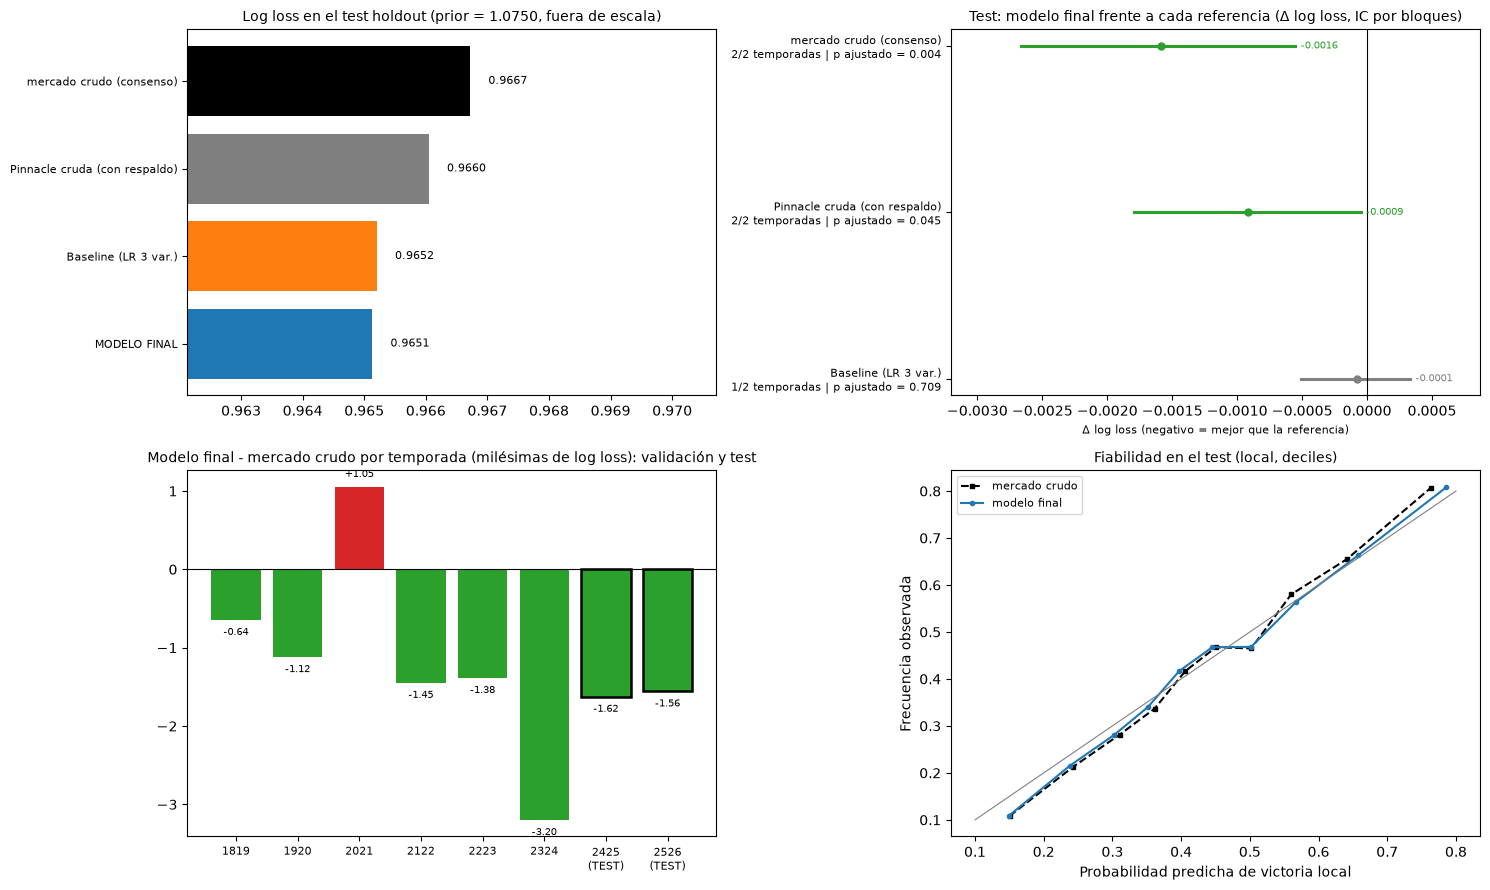

guardado: modelo_final_test.csv ( 5999 partidos )


In [12]:
# por liga, calibracion por tramo y figura
Lmk_t = loss_vec(REF_T['mercado crudo (consenso)']); filas = []
for d_ in sorted(np.unique(liga)):
    m = (liga == d_) & TEST_MASK; c = comparar(LFt, Lmk_t, mask=m)
    filas.append(dict(liga=d_, n=int(m.sum()), ll_final=float(np.nanmean(LFt[m])), ll_mercado=float(np.nanmean(Lmk_t[m])), delta=c['delta'], lo=c['lo'], hi=c['hi'], p=c['p']))
pl_t = pd.DataFrame(filas); pl_t['p_BH'] = bh(pl_t.p.values); pl_t['signif_5pct'] = pl_t.p_BH < 0.05
print('Por liga (test):'); print(pl_t.round(4).to_string(index=False))
fig, axs = plt.subplots(2, 2, figsize=(15, 9))
ref_t = [k for k in REF_T if k != 'prior (train/val)']; cl_t = {'mercado crudo (consenso)': 'black', 'Pinnacle cruda (con respaldo)': 'tab:gray', 'Baseline (LR 3 var.)': 'tab:orange', 'MODELO FINAL': 'tab:blue'}
axs[0, 0].barh(range(len(ref_t))[::-1], met_t.loc[ref_t, 'log_loss'], color=[cl_t[k] for k in ref_t]); axs[0, 0].set_yticks(range(len(ref_t))[::-1]); axs[0, 0].set_yticklabels(ref_t, fontsize=8)
lo_, hi_ = met_t.loc[ref_t, 'log_loss'].min(), met_t.loc[ref_t, 'log_loss'].max(); axs[0, 0].set_xlim(lo_ - 0.003, hi_ + 0.004)
for yi, v in zip(range(len(ref_t))[::-1], met_t.loc[ref_t, 'log_loss']): axs[0, 0].text(v + 0.0003, yi, f'{v:.4f}', va='center', fontsize=8)
axs[0, 0].set_title(f"Log loss en el test holdout (prior = {met_t.loc['prior (train/val)', 'log_loss']:.4f}, fuera de escala)", fontsize=10)
forest(axs[0, 1], [f"{r.vs}\n{r.temporadas_mejora} temporadas | p ajustado = {r.p_BH:.3f}" for r in cmp_t[cmp_t.vs != 'prior (train/val)'].itertuples()], cmp_t[cmp_t.vs != 'prior (train/val)'].delta_ll.to_numpy(), cmp_t[cmp_t.vs != 'prior (train/val)'].lo.to_numpy(), cmp_t[cmp_t.vs != 'prior (train/val)'].hi.to_numpy(), 'Test: modelo final frente a cada referencia (Δ log loss, IC por bloques)')
fol_v = [float(np.nanmean((LF - Lmk)[seas == s_])) * 1000 for s_ in FOLDS] if 'Lmk' in globals() else [float(np.nanmean((LF - loss_vec(np.where(EV[:, None], Pmk, np.nan)))[seas == s_])) * 1000 for s_ in FOLDS]
fol_t = [float(np.nanmean((LFt - Lmk_t)[seas == s_])) * 1000 for s_ in TEST_SEASONS]; etq = [str(int(s_)) for s_ in FOLDS] + [f'{int(s_)}\n(TEST)' for s_ in TEST_SEASONS]; vals = fol_v + fol_t
axs[1, 0].bar(range(len(vals)), vals, color=['tab:green' if v < 0 else 'tab:red' for v in vals], hatch=None); [axs[1, 0].patches[k].set_edgecolor('k') or axs[1, 0].patches[k].set_linewidth(1.8) for k in range(len(FOLDS), len(vals))]
axs[1, 0].axhline(0, color='k', lw=0.8); axs[1, 0].set_xticks(range(len(vals))); axs[1, 0].set_xticklabels(etq, fontsize=8); axs[1, 0].set_title('Modelo final - mercado crudo por temporada (milésimas de log loss): validación y test', fontsize=10)
for x_, v in enumerate(vals): axs[1, 0].text(x_, v + (0.1 if v >= 0 else -0.1), f'{v:+.2f}', ha='center', va='bottom' if v >= 0 else 'top', fontsize=7)
p_ = P_test[TEST_MASK][:, 0]; o_ = y[TEST_MASK] == 0; b_ = pd.qcut(p_, 10, labels=False, duplicates='drop'); pm_ = Pmk[TEST_MASK][:, 0]; bm_ = pd.qcut(pm_, 10, labels=False, duplicates='drop')
axs[1, 1].plot([pm_[bm_ == k].mean() for k in np.unique(bm_)], [o_[bm_ == k].mean() for k in np.unique(bm_)], 'k--', marker='s', ms=3, label='mercado crudo')
axs[1, 1].plot([p_[b_ == k].mean() for k in np.unique(b_)], [o_[b_ == k].mean() for k in np.unique(b_)], color='tab:blue', marker='o', ms=3, label='modelo final'); axs[1, 1].plot([0.1, 0.8], [0.1, 0.8], color='gray', lw=0.8)
axs[1, 1].set_xlabel('Probabilidad predicha de victoria local'); axs[1, 1].set_ylabel('Frecuencia observada'); axs[1, 1].set_title('Fiabilidad en el test (local, deciles)', fontsize=10); axs[1, 1].legend(fontsize=8)
plt.tight_layout(); plt.show()
# predicciones del test, en archivo aparte
pd.DataFrame(np.c_[np.where(TEST_MASK)[0], seas[TEST_MASK], y[TEST_MASK], P_test[TEST_MASK], psok[TEST_MASK].astype(int)], columns=['idx', 'Season', 'y', 'P_H', 'P_D', 'P_A', 'pinnacle_observada']).to_csv(DATA + 'modelo_final_test.csv', index=False)
print('guardado: modelo_final_test.csv (', int(TEST_MASK.sum()), 'partidos )')

**Qué encontramos.**

- **Por liga:** el modelo final mejora al mercado en 6 de 9 ligas (puntual), pero solo **Turquía** es significativo tras Benjamini–Hochberg (−0.0045, *p* ajustado = 0.009). Italia (−0.0034), Países Bajos (−0.0036) y Portugal (−0.0031) tienen el mismo signo sin ser significativos; Inglaterra (+0.0013), Francia (+0.0006) y Alemania (+0.0002) quedan peor, todas dentro del ruido.
- **Por temporada:** la diferencia con el mercado crudo es −0.0016 en 2024/25 y en 2025/26.
- **Fiabilidad:** en los deciles de victoria local las curvas del modelo final y del mercado crudo son casi idénticas y siguen la diagonal con la oscilación propia de ~600 partidos por decil (figura). Las predicciones del test están en `modelo_final_test.csv`.

**Qué significa para nuestro caso.** La idea de que la mejora viene de Portugal y Turquía **se replica solo a medias**: en validación era significativa Portugal y en test lo es Turquía, y las dos tienen signo favorable en ambos periodos. Con nueve ligas y ~600–760 partidos por liga en el test, es más prudente decir que la mejora es **pequeña y repartida**, y no atribuirla a mercados concretos.

Backtest en el test holdout (cuotas de APERTURA; tau fijo a priori):
    casa               modelo  tau  ROI_validacion  apuestas_test  ROI_test      lo      hi
    B365         MODELO FINAL 0.02          0.0509            606    0.1136 -0.0406  0.2896
    B365 Baseline (LR 3 var.) 0.02          0.0151            318    0.0454 -0.1515  0.2431
    B365        siempre local  NaN             NaN           5994   -0.0998 -0.1334 -0.0684
    B365     siempre favorito  NaN             NaN           5994   -0.0402 -0.0621 -0.0209
Pinnacle         MODELO FINAL 0.02         -0.0638            482   -0.0263 -0.1793  0.1141
Pinnacle Baseline (LR 3 var.) 0.02         -0.0484            518    0.0330 -0.1176  0.1870
Pinnacle        siempre local  NaN             NaN           4440   -0.0984 -0.1370 -0.0598
Pinnacle     siempre favorito  NaN             NaN           4440   -0.0218 -0.0438  0.0019


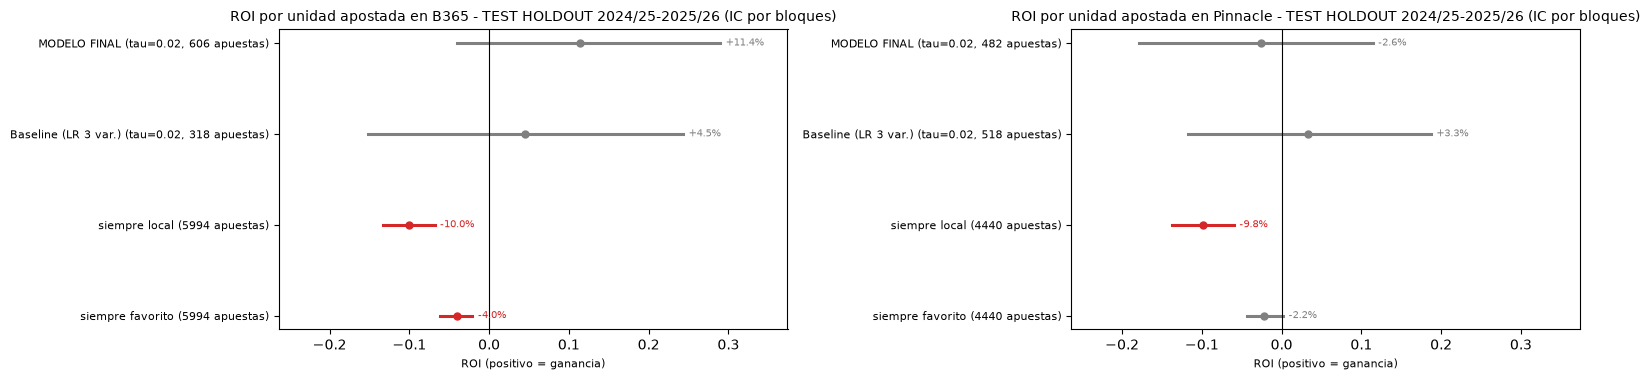

In [13]:
# backtest en el test: tau fijo a priori (TAU_APRIORI), sin optimizar; se aplica una vez al test
filas = []
for casa, O in (('B365', O_B), ('Pinnacle', O_P)):
    for modelo_, Pv, Pt in (('MODELO FINAL', P_fin, P_test), ('Baseline (LR 3 var.)', PC[A_], PA_t)):
        tau = TAU_APRIORI
        b2, p2 = apuestas(Pt, O, tau, TEST_MASK); r, lo, hi = roi_ic(b2, p2); b1, p1 = apuestas(Pv, O, tau, EV)
        filas.append(dict(casa=casa, modelo=modelo_, tau=tau, ROI_validacion=float(p1[b1].mean()) if b1.sum() else np.nan, apuestas_test=int(b2.sum()), ROI_test=r, lo=lo, hi=hi))
    fav = np.argmin(np.nan_to_num(O, nan=99), axis=1)
    for nom_r, j in (('siempre local', np.zeros(len(y), int)), ('siempre favorito', fav)):
        ok = TEST_MASK & ~np.isnan(O).any(1); pnl = np.where(y == j, O[np.arange(len(O)), j] - 1, -1.0); r, lo, hi = roi_ic(ok, pnl)
        filas.append(dict(casa=casa, modelo=nom_r, tau=np.nan, ROI_validacion=np.nan, apuestas_test=int(ok.sum()), ROI_test=r, lo=lo, hi=hi))
bt_t = pd.DataFrame(filas); print('Backtest en el test holdout (cuotas de APERTURA; tau fijo a priori):'); print(bt_t.round(4).to_string(index=False))
fig, axs = plt.subplots(1, 2, figsize=(16, 3.9), sharex=True)
for ax, casa in zip(axs, ('B365', 'Pinnacle')):
    sub_ = bt_t[bt_t.casa == casa]
    forest(ax, [f"{r.modelo} (tau={r.tau:.2f}, {r.apuestas_test} apuestas)" if r.tau == r.tau else f"{r.modelo} ({r.apuestas_test} apuestas)" for r in sub_.itertuples()], sub_.ROI_test.to_numpy(), sub_.lo.to_numpy(), sub_.hi.to_numpy(), f'ROI por unidad apostada en {casa} - TEST HOLDOUT 2024/25-2025/26 (IC por bloques)', xlabel='ROI (positivo = ganancia)', fmt='{:+.1%}', positivo_bueno=True)
plt.tight_layout(); plt.show()

**Qué encontramos.** `τ` = 0.02 fijado a priori (no optimizado) y aplicado una vez al test:

| Casa | Modelo | `τ` | ROI en validación | Apuestas en test | ROI en test | IC 95% (bloques) |
|---|---|---|---|---|---|---|
| B365 | **Modelo final** | 0.02 | +5.1% | 606 | **+11.4%** | [−4.1%, +29.0%] |
| B365 | Baseline (LR) | 0.02 | +1.5% | 318 | +4.5% | [−15.2%, +24.3%] |
| B365 | siempre local | — | — | 5,994 | −10.0% | [−13.3%, −6.8%] |
| B365 | siempre favorito | — | — | 5,994 | −4.0% | [−6.2%, −2.1%] |
| Pinnacle | **Modelo final** | 0.02 | −6.4% | 482 | −2.6% | [−17.9%, +11.4%] |
| Pinnacle | Baseline (LR) | 0.02 | −4.8% | 518 | +3.3% | [−11.8%, +18.7%] |
| Pinnacle | siempre local | — | — | 4,440 | −9.8% | [−13.7%, −6.0%] |
| Pinnacle | siempre favorito | — | — | 4,440 | −2.2% | [−4.4%, +0.2%] |

**Qué significa para nuestro caso.** Con Pinnacle el modelo final no se distingue de 0 (−2.6%, intervalo que incluye +11.4%; solo 482 apuestas con `τ` = 0.02). Con Bet365 la estimación puntual es positiva (+11.4% en 606 apuestas, frente a +5.1% en validación), pero **el intervalo incluye pérdidas** (−4.1%) y el baseline, con el mismo `τ`, da +4.5%, por lo que **no se puede afirmar rentabilidad**. En Pinnacle solo se cubren los 4,440 partidos con precio observado (la cobertura de 2025/26 es 47.8 %). La conclusión se mantiene: no se detecta un retorno significativamente positivo; las cuotas de apertura de Bet365 son además de difícil acceso en la práctica (límites a cuentas ganadoras, cuotas que se mueven).

## Resumen del modelo final

| Aspecto | Decisión / resultado |
|---|---|
| **Modelo** | Regresión logística multinomial estandarizada, `C = 0.01`, sobre 2 variables: `REF_logit = ln(pH/pA)` y `REF_pD` |
| **Precio de referencia** | Cuotas de **apertura** de Pinnacle (95.4% de los partidos); respaldo: consenso de B365, BW, WH y PS |
| **Qué se quitó** | `MKT_margin` (no estacionaria, PSI 0.6–1.5); plantilla, forma y habilidades (no aportan sobre el precio) |
| **Log loss, validación (6 temporadas, 2018/19–2023/24)** | **0.9653**; mercado crudo 0.9664; baseline (LR de 3 variables) 0.9657; prior 1.0720 |
| **Log loss, test holdout (2024/25–2025/26)** | **0.9651**; mercado crudo 0.9667; Pinnacle cruda 0.9660; baseline 0.9652; prior 1.0750 |
| **Frente al mercado** | Validación: −0.0011 [−0.0018, −0.0004], 5/6, *p* ajustado 0.004. **Test: −0.0016 [−0.0027, −0.0006], 2/2, *p* ajustado 0.004** (frente a Pinnacle cruda: −0.0009, *p* ajustado 0.045; frente al baseline: −0.0001, sin diferencia) |
| **Discriminación** | AUC macro 0.684 (igual al mercado); empate 0.588 |
| **Calibración** | ECE validación 0.0093 (mercado 0.0143); test 0.0168 (mercado 0.0221); pendientes 1.05–1.09 |
| **Corrección por liga** | Se probó un intercepto por liga (con y sin encogimiento): empeora (+0.0003 a +0.0004); no se usa |
| **Dónde mejora** | Mejora pequeña y repartida: significativa tras BH solo en Portugal (validación) y en Turquía (test); no se atribuye a ligas concretas |
| **Dinero** | Test (`τ` = 0.02 fijo a priori): ROI Pinnacle −2.6% [−17.9%, +11.4%]; B365 +11.4% [−4.1%, +29.0%] (no significativo): no se detecta retorno positivo |
| **Entrenamiento** | Solo train/val (30,120 partidos, 2014/15–2023/24); el test holdout (2024/25–2025/26, 5,999 partidos) solo se evaluó en el Paso 8 |
| **Archivos** | `modelo_final.json`, `modelo_final.joblib`, `modelo_final_oof.csv`, `modelo_final_test.csv` |

**Lectura global.** El modelo final es el de menor log loss de los probados, pero su ventaja sobre el baseline es nula en test y sobre Pinnacle cruda está en el límite de la significación; es un refinamiento (corregir la subconfianza del precio), no información nueva, y casi todo está en los partidos con Pinnacle observada: la conclusión central del proyecto —el mercado es eficiente respecto a la información de fundamentos disponible— se mantiene.

**Limitaciones.** (1) En 2025/26 Pinnacle cubre 48% de los partidos, así que esa temporada se parece más al consenso. (2) La mejora por liga no es estable entre validación y test. (3) Las cuotas se asumen de apertura; usar cuotas de cierre como entrada sería una fuga. (4) El modelo da probabilidades, no recomendaciones de apuesta. (5) Sesgo de selección: variables, reglas y modelo se eligieron mirando las mismas 6 temporadas de validación con las que se reportan los *p*; solo el test está libre de él. (6) El test mezcla Pinnacle observada y respaldo de consenso: ver el desglose del Paso 8.